# Fifteen-class results: review-level and game-level performance, proximity, and review characteristics

Inputs: the sample built by `design_15class_sampling.ipynb` and the out-of-fold probabilities produced on
the cluster by `cluster/train_folds.py` (one 15-class vector and one auxiliary 5-pool vector per review).
Every number below is out of fold: a review is scored by a model that never saw it, and a pool game is
scored by a model that never saw any review of that game.

1. Load and check the out-of-fold predictions
2. Review-level performance: all 15 classes, focal classes, pool classes
3. Game-level performance for the pools: one number per held-out game, averaged equally across games
4. What the classifier predicts: mean-probability and confusion heatmaps
5. A per-review information score
6. Information by review length and by calendar year
7. Proximity of focal games to the pools: descriptor-based and review-based
8. Score by funny votes, verdict and helpfulness, across years

Outputs go to `results/design15/`.

## 0. Setup

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
import json
from fractions import Fraction
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
OUT = ROOT / "results" / "design15"
OOF = OUT / "cluster"
SEED = 42
N_FOLDS = 5
CLASSES = [f"F{j}" for j in range(1, 11)] + [f"G{m}" for m in range(1, 6)]
FOCAL, POOLS = CLASSES[:10], CLASSES[10:]
K = len(CLASSES)
H_Y = np.log2(K)
LN2 = np.log(2)
YEARS = list(range(2015, 2025))
GROUP_LABELS = {"G1": "shooters / combat", "G2": "RPG / narrative adventure", "G3": "survival / crafting",
                "G4": "simulation / creative / physics", "G5": "strategy / management"}
plt.rcParams.update({"figure.dpi": 110, "axes.titlelocation": "left"})

df = pd.read_parquet(OUT / "sample_15class.parquet")
CLASS_NAME = dict(zip(df["cls"], df["game"]))          # focal: game name; pools overwritten below
for m in POOLS:
    CLASS_NAME[m] = m
SHORT = {**{c: CLASS_NAME[c] for c in FOCAL}, **{m: m for m in POOLS}}
print(f"{len(df):,} reviews, {df['appid'].nunique()} games, {df['cls'].nunique()} classes")


1,500,000 reviews, 100 games, 15 classes


## 1. Load and check the out-of-fold predictions

In [2]:
n = len(df)
P = np.full((n, K), np.nan, dtype=np.float32)        # 15-class model
Q = np.full((n, 5), np.nan, dtype=np.float32)        # auxiliary 5-pool model (fitted on pool reviews only)
covered = np.zeros(n, dtype=int)
tuning = []
for k in range(N_FOLDS):
    z = np.load(OOF / f"oof_fold{k}.npz")
    rows = z["rows"]
    assert (df["fold"].to_numpy()[rows] == k).all()
    P[rows] = z["proba15"]
    Q[rows] = z["proba_pool5"]
    covered[rows] += 1
    s = json.load(open(OOF / f"fold{k}_summary.json"))
    for model in ("main", "pool5"):
        for g in s[model]["grid"]:
            tuning.append(dict(fold=k, model=model, C=g["C"], inner_log_loss_bits=g["inner_log_loss_bits"],
                               inner_balanced_accuracy=g["inner_balanced_accuracy"], n_iter=g["n_iter"],
                               chosen=g["C"] == s[model]["chosen_C"]))
assert (covered == 1).all() and np.isfinite(P).all() and np.isfinite(Q).all()
assert np.allclose(P.sum(1), 1, atol=1e-4) and np.allclose(Q.sum(1), 1, atol=1e-4)
tuning = pd.DataFrame(tuning)
tuning.to_csv(OUT / "tuning_summary.csv", index=False)

y = df["class_idx"].to_numpy()
p_true = np.clip(P[np.arange(n), y], 1e-12, 1)
df["nll"] = -np.log2(p_true)                 # per-review held-out surprise, bits
df["s"] = H_Y - df["nll"]                    # per-review information against the uniform 15-class prior
df["hit"] = (P.argmax(1) == y)
df["p_true"] = p_true
is_focal = df["cls"].isin(FOCAL).to_numpy()
print("every review scored exactly once by a model that did not see it")
tuning.pivot_table(index=["model", "C"], columns="fold", values="inner_log_loss_bits").round(4)


every review scored exactly once by a model that did not see it


fold              0       1       2       3       4
model C                                            
main  0.1    3.1022  3.1253  3.0665  3.0368  3.1389
      1.0    3.1023  3.1253  3.0665  3.0370  3.1390
      10.0   3.1024  3.1253  3.0666  3.0368  3.1390
      100.0  3.1023  3.1254  3.0666  3.0368  3.1391
pool5 0.1    2.1579  2.2317  2.2822  2.1911  2.2688
      1.0    2.1583  2.2320  2.2825  2.1911  2.2690
      10.0   2.1583  2.2317  2.2826  2.1910  2.2689
      100.0  2.1583  2.2319  2.2824  2.1915  2.2690

**What this shows.** The ridge strength chosen on the inner game-held-out split is the same in every fold
for the main model (the row marked in `tuning_summary.csv`), so the five fold models are comparable.

## 2. Review-level performance

Accuracy and log loss (bits) of the 15-class model, over all reviews and separately for reviews of the
focal games and reviews of the pool games. Because each class holds 100,000 reviews, the simple mean is
also the class-balanced mean, and the reference prior is $1/15$ ($H(Y)=\log_2 15 = 3.907$ bits).
The information column is $I = H(Y) - H(Y\mid X)$, estimated by the mean held-out surprise.

In [3]:
def perf(sub):
    return pd.Series({"n": len(sub), "accuracy": sub["hit"].mean(), "log_loss_bits": sub["nll"].mean(),
                      "information_bits": H_Y - sub["nll"].mean(), "I_norm": 1 - sub["nll"].mean() / H_Y,
                      "mean_p_true": sub["p_true"].mean()})

per_class = df.groupby("cls").apply(perf).reindex(CLASSES)
per_class.insert(0, "name", [CLASS_NAME[c] for c in CLASSES])
summary = pd.DataFrame({"all 15 classes": perf(df), "focal classes": perf(df[is_focal]),
                        "pool classes": perf(df[~is_focal])}).T
summary["n"] = summary["n"].astype(int)
per_class.to_csv(OUT / "performance_per_class.csv")
summary.to_csv(OUT / "performance_review_level.csv")
display(summary.round(4))
per_class.round(4)


,n,accuracy,log_loss_bits,information_bits,I_norm,mean_p_true
all 15 classes,1500000,0.3304,3.0735,0.8334,0.2133,0.2331
focal classes,1000000,0.4014,2.7854,1.1215,0.2870,0.2789
pool classes,500000,0.1885,3.6496,0.2573,0.0659,0.1414


,name,n,accuracy,log_loss_bits,information_bits,I_norm,mean_p_true
cls,,,,,,,
F1,7 Days to Die,100000.0,0.3825,2.8615,1.0454,0.2676,0.2557
F2,BeamNG.drive,100000.0,0.5086,2.5419,1.3649,0.3494,0.3358
F3,Dead by Daylight,100000.0,0.3435,2.9204,0.9865,0.2525,0.2462
F4,Fallout 4,100000.0,0.3649,2.8844,1.0225,0.2617,0.2550
F5,PAYDAY 2,100000.0,0.3560,2.9729,0.9340,0.2391,0.2424
F6,Paladins,100000.0,0.4108,2.7138,1.1931,0.3054,0.3086
F7,Stardew Valley,100000.0,0.4834,2.5417,1.3652,0.3494,0.3377
F8,Unturned,100000.0,0.2479,3.2004,0.7065,0.1808,0.1606
F9,VRChat,100000.0,0.4908,2.5350,1.3719,0.3512,0.3292


Restricting the prediction to the classes of one type gives a second reading: how well the model separates
the ten focal games from each other when the answer is known to be a focal game, and how well it separates
the five pools when the answer is known to be a pool. These restricted numbers are what the earlier
ten-game analysis measured.

In [4]:
def restricted(mask, cols):
    sub = P[mask][:, cols]
    sub = sub / sub.sum(1, keepdims=True)
    yy = y[mask] - cols[0]
    pt = np.clip(sub[np.arange(len(yy)), yy], 1e-12, 1)
    Hc = np.log2(len(cols))
    return pd.Series({"n": int(mask.sum()), "classes": len(cols), "H(Y)_bits": Hc,
                      "accuracy": float((sub.argmax(1) == yy).mean()),
                      "log_loss_bits": float(-np.log2(pt).mean()),
                      "information_bits": float(Hc + np.log2(pt).mean())})
restricted_tab = pd.DataFrame({"focal games only (10-way)": restricted(is_focal, list(range(10))),
                               "pools only (5-way)": restricted(~is_focal, list(range(10, 15)))}).T
restricted_tab.to_csv(OUT / "performance_restricted.csv")
restricted_tab.round(4)


,n,classes,H(Y)_bits,accuracy,log_loss_bits,information_bits
focal games only (10-way),1000000.0,10.0,3.3219,0.4504,2.2956,1.0263
pools only (5-way),500000.0,5.0,2.3219,0.3701,2.1976,0.1243


## 3. Game-level performance for the pools

For the pool classes the unit that was held out is the game, so the natural unit of evaluation is also the
game. Each of the 90 pool games gets its own accuracy and log loss from the fold in which it was held out;
these are then averaged with equal weight across the games of a pool, and across all 90. The uncertainty
is assessed at the game level: the standard error across games, and a bootstrap that resamples games
within each pool.

In [5]:
pool_df = df[~is_focal]
game = (pool_df.groupby(["cls", "appid", "game", "fold"])
               .agg(n=("hit", "size"), accuracy=("hit", "mean"), log_loss_bits=("nll", "mean"),
                    mean_p_true=("p_true", "mean"))
               .reset_index())
game["information_bits"] = H_Y - game["log_loss_bits"]
game.to_csv(OUT / "performance_per_game.csv", index=False)

rng = np.random.default_rng(SEED)
B = 2000
def game_level(g):
    acc, ll = g["accuracy"].to_numpy(), g["log_loss_bits"].to_numpy()
    m = len(g)
    boot_acc = np.array([acc[rng.integers(m, size=m)].mean() for _ in range(B)])
    boot_ll = np.array([ll[rng.integers(m, size=m)].mean() for _ in range(B)])
    return pd.Series({"games": m, "reviews": int(g["n"].sum()),
                      "accuracy_equal_game": acc.mean(), "accuracy_se": acc.std(ddof=1) / np.sqrt(m),
                      "accuracy_ci_lo": np.percentile(boot_acc, 2.5), "accuracy_ci_hi": np.percentile(boot_acc, 97.5),
                      "log_loss_equal_game": ll.mean(), "log_loss_se": ll.std(ddof=1) / np.sqrt(m),
                      "log_loss_ci_lo": np.percentile(boot_ll, 2.5), "log_loss_ci_hi": np.percentile(boot_ll, 97.5),
                      "accuracy_review_weighted": np.average(acc, weights=g["n"]),
                      "log_loss_review_weighted": np.average(ll, weights=g["n"]),
                      "worst_game": g.loc[g["accuracy"].idxmin(), "game"], "best_game": g.loc[g["accuracy"].idxmax(), "game"]})

# the all-pools row is the mean over all 90 games; its bootstrap resamples games within each pool
def all_pools(g):
    out = game_level(g)
    acc = [sub["accuracy"].to_numpy() for _, sub in g.groupby("cls")]
    ll = [sub["log_loss_bits"].to_numpy() for _, sub in g.groupby("cls")]
    boot_acc = [np.concatenate([a[rng.integers(len(a), size=len(a))] for a in acc]).mean() for _ in range(B)]
    boot_ll = [np.concatenate([a[rng.integers(len(a), size=len(a))] for a in ll]).mean() for _ in range(B)]
    out["accuracy_ci_lo"], out["accuracy_ci_hi"] = np.percentile(boot_acc, [2.5, 97.5])
    out["log_loss_ci_lo"], out["log_loss_ci_hi"] = np.percentile(boot_ll, [2.5, 97.5])
    return out

pool_level = pd.concat([game.groupby("cls").apply(game_level), pd.DataFrame({"all pools": all_pools(game)}).T])
pool_level.to_csv(OUT / "performance_pool_game_level.csv")
pool_level.round(4)


,games,reviews,accuracy_equal_game,accuracy_se,accuracy_ci_lo,accuracy_ci_hi,log_loss_equal_game,log_loss_se,log_loss_ci_lo,log_loss_ci_hi,accuracy_review_weighted,log_loss_review_weighted,worst_game,best_game
G1,40,100000,0.115743,0.01013,0.097029,0.136359,3.624655,0.045976,3.529061,3.712115,0.11933,3.614828,Muse Dash,Insurgency: Sandstorm
G2,25,100000,0.279068,0.02168,0.235912,0.320355,3.30243,0.099659,3.120525,3.495919,0.2736,3.331234,Trove,Grim Dawn
G3,6,100000,0.187698,0.027546,0.142664,0.239831,3.659171,0.187917,3.330504,4.006034,0.18959,3.649997,Scrap Mechanic,The Long Dark
G4,8,100000,0.067026,0.016096,0.040594,0.098077,4.490513,0.160458,4.190831,4.793839,0.07064,4.440064,theHunter: Call of the Wild™,Human: Fall Flat
G5,11,100000,0.274478,0.028375,0.219489,0.327367,3.283955,0.135947,3.049823,3.545453,0.28927,3.211829,Totally Accurate Battle Simulator,Europa Universalis IV
all pools,90,500000,0.180979,0.012132,0.165669,0.196792,3.572773,0.05408,3.492746,3.652733,0.188486,3.64959,theHunter: Call of the Wild™,Grim Dawn


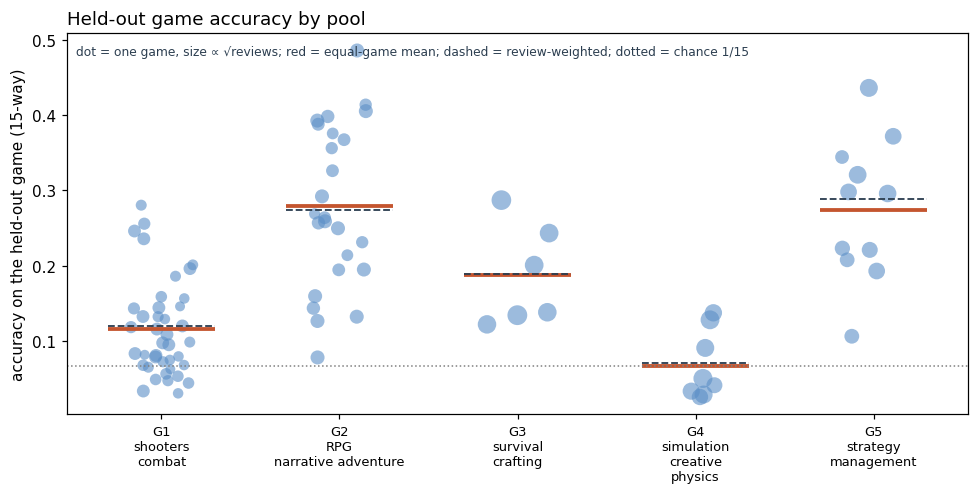

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.6))
for i, m in enumerate(POOLS):
    g = game[game["cls"] == m]
    jitter = rng.uniform(-0.18, 0.18, len(g))
    ax.scatter(i + jitter, g["accuracy"], s=np.sqrt(g["n"]) * 1.2, alpha=0.6, color="#5B8FC7", edgecolor="none")
    ax.hlines(pool_level.loc[m, "accuracy_equal_game"], i - 0.3, i + 0.3, color="#C4552F", lw=2.5)
    ax.hlines(pool_level.loc[m, "accuracy_review_weighted"], i - 0.3, i + 0.3, color="#2C3E50", lw=1.2, ls="--")
ax.axhline(1 / K, color="grey", ls=":", lw=1)
ax.set_xticks(range(5), [f"{m}\n{GROUP_LABELS[m].replace(' / ', chr(10))}" for m in POOLS], fontsize=8.5)
ax.set_ylabel("accuracy on the held-out game (15-way)")
ax.set_title("Held-out game accuracy by pool", fontsize=12)
ax.text(0.01, 0.97, "dot = one game, size ∝ √reviews; red = equal-game mean; dashed = review-weighted; dotted = chance 1/15",
        transform=ax.transAxes, fontsize=8, va="top", color="#2C3E50")
fig.tight_layout()
fig.savefig(OUT / "game_level_accuracy.png", dpi=140)
plt.show()


**How to read this.** For the focal classes the test is recognition of new reviews of games present in training.
For the pools it is generalisation to unseen games within known genre groups: a held-out survival game has to
be recognised as $G_3$ from patterns learned on the other survival games. All five pool labels remain in training,
so this is not open-set classification, and "unseen" refers to the supervised classifier, not to the frozen
encoder's pretraining. The spread of the dots is the honest picture of that generalisation: a pool's equal-game
mean can hide games the model places almost entirely elsewhere.

## 4. What the classifier predicts

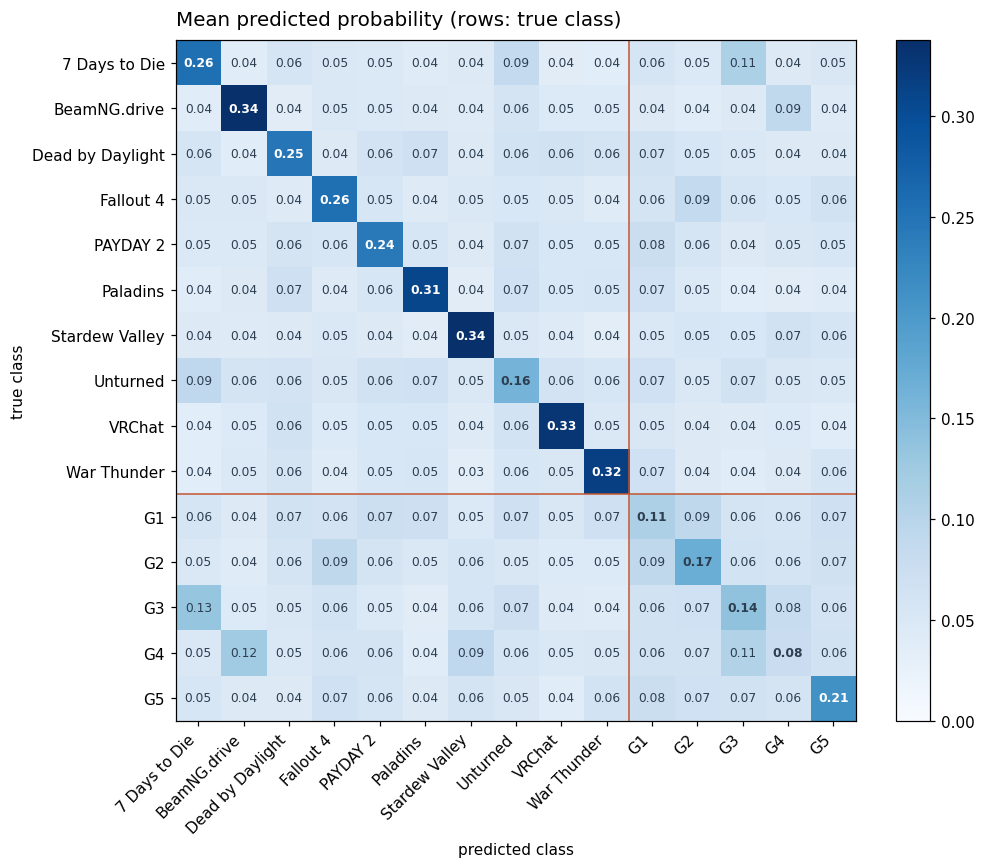

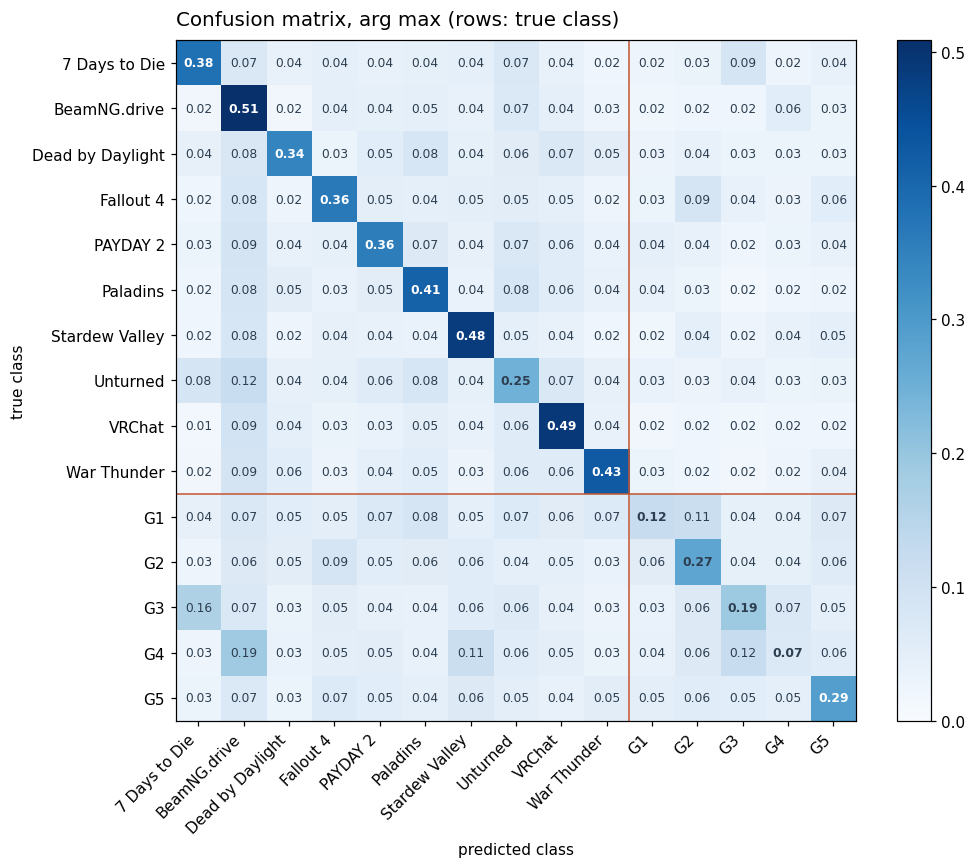

In [7]:
names = [SHORT[c] for c in CLASSES]
pred = P.argmax(1)
P_soft = pd.DataFrame([P[y == i].mean(0) for i in range(K)], index=names, columns=names)
P_hard = pd.DataFrame([np.bincount(pred[y == i], minlength=K) / (y == i).sum() for i in range(K)], index=names, columns=names)
P_soft.round(4).to_csv(OUT / "heatmap_mean_probability15.csv")
P_hard.round(4).to_csv(OUT / "heatmap_confusion15.csv")

for M, fname, ttl in [(P_soft, "heatmap_probability15.png", "Mean predicted probability (rows: true class)"),
                      (P_hard, "heatmap_confusion15.png", "Confusion matrix, arg max (rows: true class)")]:
    A = M.to_numpy()
    fig, ax = plt.subplots(figsize=(9.2, 8))
    im = ax.imshow(A, cmap="Blues", vmin=0, vmax=A.max())
    ax.set_xticks(range(K), names, rotation=45, ha="right", fontsize=10)
    ax.set_yticks(range(K), names, fontsize=10)
    ax.axhline(9.5, color="#C4552F", lw=1); ax.axvline(9.5, color="#C4552F", lw=1)
    ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.set_title(ttl, fontsize=13, pad=10)
    hi = A.max() * 0.55
    for r in range(K):
        for c in range(K):
            ax.text(c, r, f"{A[r, c]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if A[r, c] > hi else "#2C3E50", fontweight="bold" if r == c else "normal")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(OUT / fname, dpi=140)
    plt.show()


## 5. A per-review information score

$s_i = \log_2 \hat p(Y_i \mid X_i) + \log_2 15$: how many bits the review moved the model toward its true
class relative to the uniform prior. Its mean is the information estimate of section 2.

mean s = 0.833 bits, median 0.635, share s > 0: 66.6%


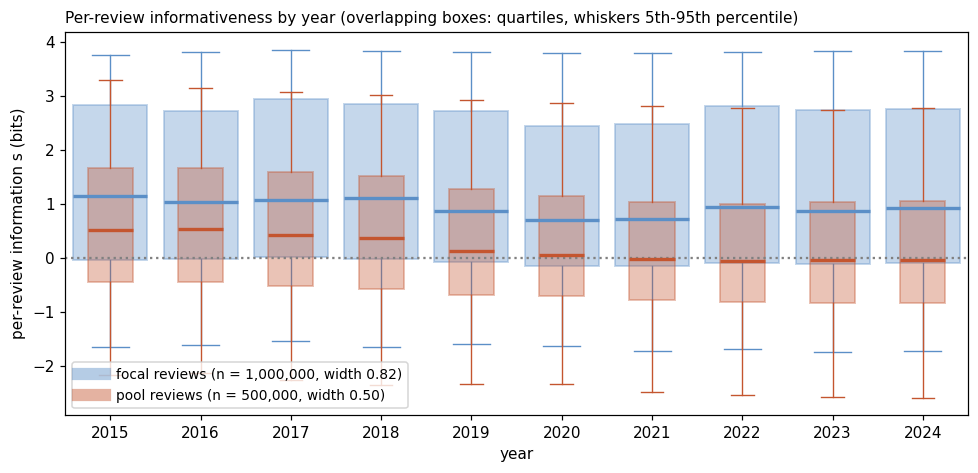

most informative:


,text,game,cls,word_count,s
966137,Fun game but If you want good tanks or airplan...,War Thunder,F10,13,3.91
926352,grind a gaijin,War Thunder,F10,3,3.91
909034,i love planes and i hate the grind,War Thunder,F10,8,3.91
991521,nice planes and tanks but arduous grind,War Thunder,F10,7,3.91
827215,met alot of weird people on vrc but also met a...,VRChat,F9,23,3.91
577852,"Overwatch with better heroes, but free.",Paladins,F6,6,3.91


least informative:


,text,game,cls,word_count,s
755070,i love everything but the driving physics.,Unturned,F8,7,-11.38
1473184,aircraft,Factorio,G5,1,-11.35
1358351,farm,Slime Rancher,G4,1,-11.21
754759,Red Hills and physics of car,Unturned,F8,6,-11.04
27412,gotta get those grand prix points,7 Days to Die,F1,6,-10.90
1364230,very cute and relaxing farming game,Slime Rancher,G4,6,-10.81


In [8]:
print(f"mean s = {df['s'].mean():.3f} bits, median {df['s'].median():.3f}, share s > 0: {(df['s'] > 0).mean():.1%}")
# distribution of s by year, focal and pool reviews overlapping (larger group wider)
fig, ax = plt.subplots(figsize=(9, 4.4))
s_arr, y_arr = df["s"].to_numpy(), df["year"].to_numpy()
for lab, mask, color, width in [("focal reviews", is_focal, "#5B8FC7", 0.82), ("pool reviews", ~is_focal, "#C4552F", 0.5)]:
    data = [np.clip(s_arr[mask & (y_arr == yr)], -8, H_Y) for yr in YEARS]
    bp = ax.boxplot(data, positions=range(len(YEARS)), widths=width, showfliers=False, patch_artist=True, whis=(5, 95),
                    medianprops=dict(color=color, lw=2.2), whiskerprops=dict(color=color, lw=0.9), capprops=dict(color=color, lw=0.9))
    for b in bp["boxes"]:
        b.set(facecolor=color, alpha=0.35, edgecolor=color, lw=1.3)
    ax.plot([], [], color=color, lw=8, alpha=0.45, label=f"{lab} (n = {int(mask.sum()):,}, width {width:.2f})")
ax.axhline(0, color="grey", ls=":"); ax.set_xticks(range(len(YEARS)), YEARS)
ax.set_xlabel("year"); ax.set_ylabel("per-review information s (bits)"); ax.legend(loc="lower left", fontsize=9)
ax.set_title("Per-review informativeness by year (overlapping boxes: quartiles, whiskers 5th-95th percentile)", fontsize=10)
fig.tight_layout(); fig.savefig(OUT / "s_by_year_overlap_box.png", dpi=140); plt.show()
s_year = (df.assign(kind=np.where(is_focal, "focal", "pool")).groupby(["kind", "year"])["s"]
            .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(3))
s_year.to_csv(OUT / "s_by_year_quantiles.csv")

show = df.assign(text=df["text"].str.slice(0, 90))[["text", "game", "cls", "word_count", "s"]]
print("most informative:"); display(show.nlargest(6, "s").round(2))
print("least informative:"); display(show.nsmallest(6, "s").round(2))


## 6. Information by review length and by calendar year

Means of $s$ with 95% intervals. For focal reviews the interval is the design-consistent one of the earlier
analysis (strata = games). For pool reviews the independent units are games, so the mean is taken with equal
weight per game and the interval comes from the spread across games.

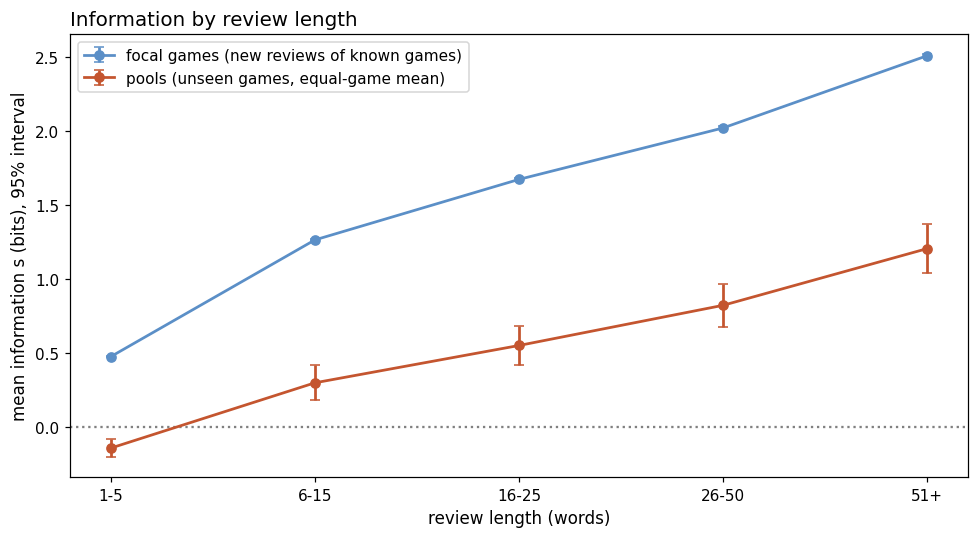

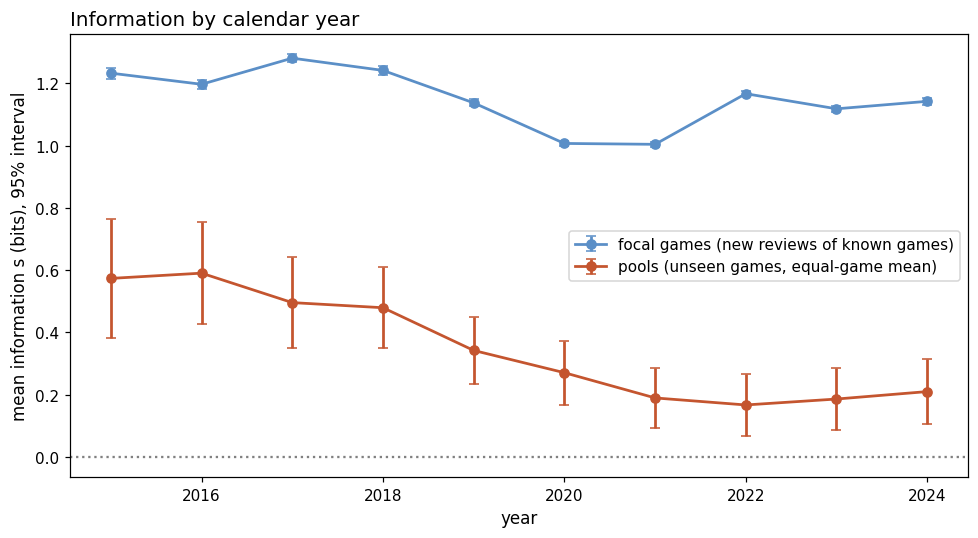

,bucket,n_focal,n_pool,n_pool_games,mean_words,focal_s,focal_lo,focal_hi,pool_s,pool_lo,pool_hi
0,1-5,461691,187021,90,2.430,0.475,0.471,0.480,-0.143,-0.204,-0.083
1,6-15,255131,127019,90,9.676,1.265,1.258,1.272,0.298,0.181,0.416
2,16-25,101526,57714,90,19.882,1.674,1.663,1.685,0.551,0.418,0.684
3,26-50,95420,61398,90,35.721,2.022,2.012,2.032,0.822,0.675,0.970
4,51+,86232,66848,90,123.047,2.510,2.501,2.520,1.206,1.038,1.374


,year,n_focal,n_pool,n_pool_games,mean_words,focal_s,focal_lo,focal_hi,pool_s,pool_lo,pool_hi
0,2015,36750,45575,34,35.654,1.233,1.215,1.250,0.574,0.384,0.764
1,2016,57092,50495,53,34.968,1.197,1.183,1.211,0.590,0.427,0.753
2,2017,75613,50495,68,31.178,1.281,1.268,1.293,0.496,0.349,0.643
3,2018,50413,50495,77,32.590,1.241,1.226,1.257,0.479,0.349,0.610
4,2019,88401,50490,90,22.227,1.137,1.126,1.149,0.342,0.234,0.450
5,2020,153187,50490,90,17.732,1.007,0.998,1.015,0.271,0.169,0.373
6,2021,162637,50490,90,16.656,1.004,0.996,1.013,0.190,0.092,0.288
7,2022,151069,50490,90,17.397,1.167,1.158,1.176,0.167,0.069,0.266
8,2023,115381,50490,90,16.277,1.118,1.108,1.129,0.186,0.086,0.287
9,2024,109457,50490,72,15.663,1.142,1.132,1.153,0.210,0.106,0.315


In [9]:
def se_strata(values, strata):
    g = pd.Series(values).groupby(np.asarray(strata))
    n_y, s2_y = g.size().to_numpy(), g.var(ddof=1).to_numpy()
    return float(np.sqrt(np.nansum(n_y * np.nan_to_num(s2_y))) / len(values))

def focal_stat(sub):
    v = sub["s"].to_numpy()
    se = se_strata(v, sub["appid"].to_numpy()) if len(sub) > 1 else np.nan
    return v.mean(), v.mean() - 1.96 * se, v.mean() + 1.96 * se

def pool_stat(sub):
    per_game = sub.groupby("appid")["s"].mean()
    m = per_game.mean()
    se = per_game.std(ddof=1) / np.sqrt(len(per_game)) if len(per_game) > 1 else np.nan
    return m, m - 1.96 * se, m + 1.96 * se

edges = [0, 5, 15, 25, 50, np.inf]
LABELS = ["1-5", "6-15", "16-25", "26-50", "51+"]
df["bucket"] = pd.cut(df["word_count"], bins=edges, labels=False).astype(int)

def table(by):
    rows = []
    for key, sub in df.groupby(by):
        f, g = sub[sub["cls"].isin(FOCAL)], sub[~sub["cls"].isin(FOCAL)]
        fm, flo, fhi = focal_stat(f)
        gm, glo, ghi = pool_stat(g)
        rows.append({by: key, "n_focal": len(f), "n_pool": len(g), "n_pool_games": g["appid"].nunique(),
                     "mean_words": sub["word_count"].mean(),
                     "focal_s": fm, "focal_lo": flo, "focal_hi": fhi, "pool_s": gm, "pool_lo": glo, "pool_hi": ghi})
    return pd.DataFrame(rows)

by_len = table("bucket"); by_len["bucket"] = LABELS
by_year = table("year")
by_len.round(4).to_csv(OUT / "info_by_length15.csv", index=False)
by_year.round(4).to_csv(OUT / "info_by_year15.csv", index=False)

for t, xcol, xt, xlabel, title, fname in [(by_len, np.arange(len(by_len)), by_len["bucket"], "review length (words)", "Information by review length", "info_by_length15.png"),
                                            (by_year, by_year["year"], None, "year", "Information by calendar year", "info_by_year15.png")]:
    fig, a = plt.subplots(figsize=(9, 5))
    for pre, lab, c in [("focal", "focal games (new reviews of known games)", "#5B8FC7"),
                        ("pool", "pools (unseen games, equal-game mean)", "#C4552F")]:
        a.errorbar(xcol, t[f"{pre}_s"], yerr=[t[f"{pre}_s"] - t[f"{pre}_lo"], t[f"{pre}_hi"] - t[f"{pre}_s"]],
                   marker="o", capsize=3, label=lab, color=c, lw=1.8, ms=6)
    a.axhline(0, color="grey", ls=":"); a.set_ylabel("mean information s (bits), 95% interval", fontsize=11); a.legend(fontsize=10)
    if xt is not None:
        a.set_xticks(xcol, xt)
    a.set_xlabel(xlabel, fontsize=11); a.set_title(title, fontsize=13); a.tick_params(labelsize=10)
    fig.tight_layout(); fig.savefig(OUT / fname, dpi=140); plt.show()
display(by_len.round(3)); by_year.round(3)


### 6b. Per-game distributions of the held-out probability, year by year

For each focal game, the distribution of $\hat p(Y_i \mid X_i)$, the probability the model placed on the
correct class, one box per year. These are the raw distributions that every average summarises.

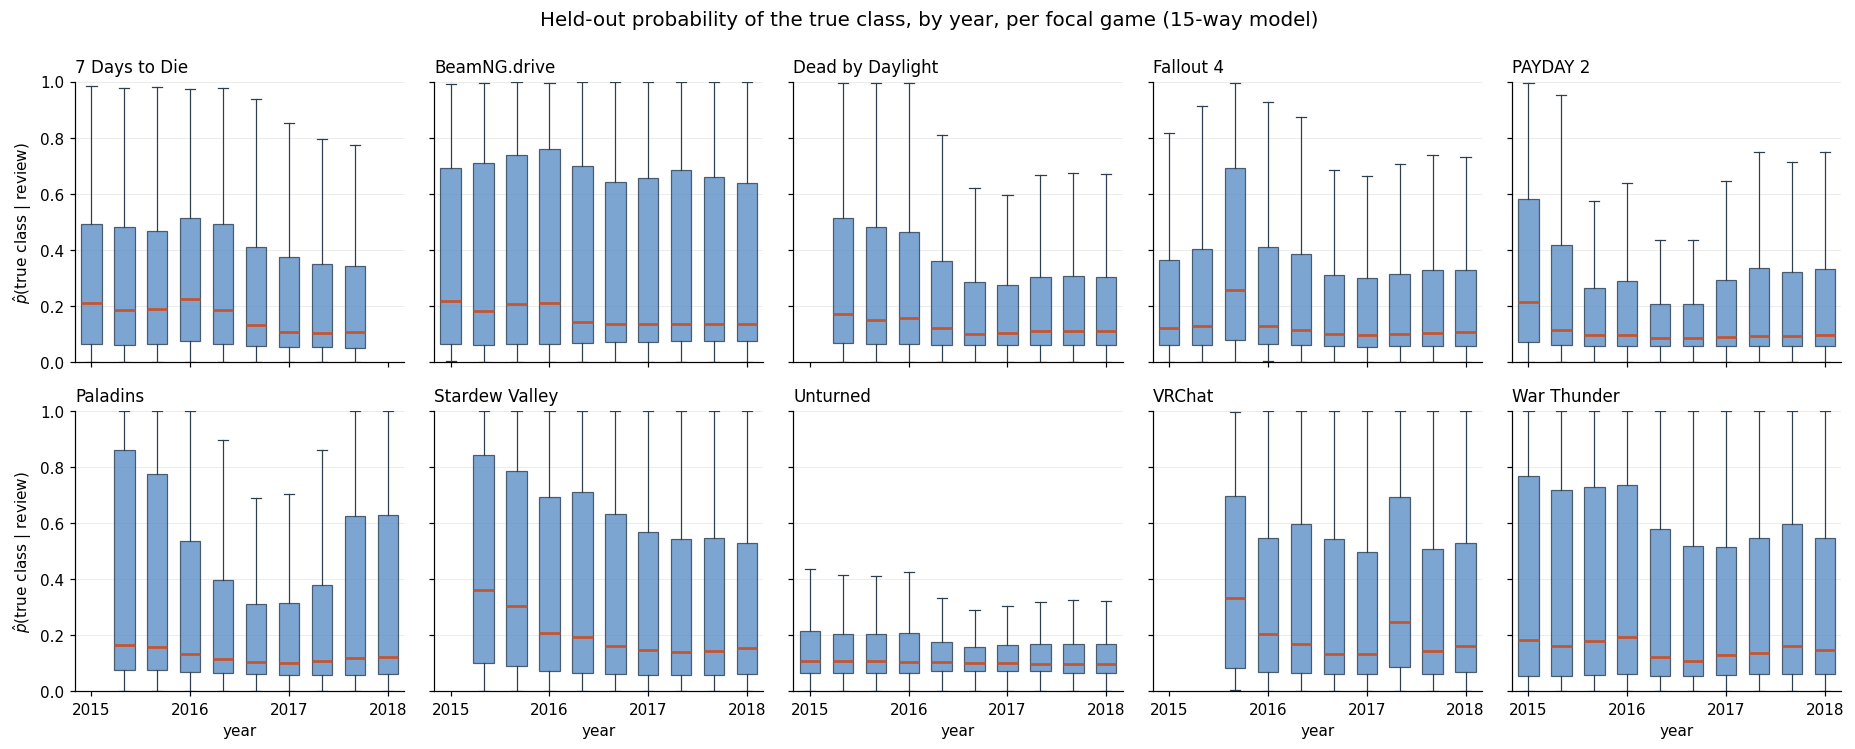

year,game,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
cls,,,,,,,,,,,
F1,7 Days to Die,0.21,0.18,0.19,0.23,0.19,0.13,0.11,0.10,0.11,NaN
F2,BeamNG.drive,0.22,0.18,0.21,0.21,0.14,0.14,0.14,0.14,0.14,0.14
F3,Dead by Daylight,NaN,0.17,0.15,0.16,0.12,0.10,0.10,0.11,0.11,0.11
F4,Fallout 4,0.12,0.13,0.26,0.13,0.11,0.10,0.10,0.10,0.10,0.11
F5,PAYDAY 2,0.21,0.11,0.10,0.10,0.09,0.09,0.09,0.09,0.09,0.10
F6,Paladins,NaN,0.16,0.16,0.13,0.11,0.11,0.10,0.11,0.12,0.12
F7,Stardew Valley,NaN,0.36,0.31,0.21,0.19,0.16,0.15,0.14,0.14,0.15
F8,Unturned,0.11,0.11,0.11,0.11,0.10,0.10,0.10,0.10,0.10,0.10
F9,VRChat,NaN,NaN,0.33,0.21,0.17,0.13,0.13,0.25,0.15,0.16


In [10]:
MIN_N = 30
VIO, IQR, TREND = "#5B8FC7", "#2C3E50", "#C4552F"
def year_boxes(ax, sub):
    years = [yr for yr in YEARS if (sub["year"] == yr).sum() >= MIN_N]
    data = [sub.loc[sub["year"] == yr, "p_true"].to_numpy() for yr in years]
    bp = ax.boxplot(data, positions=years, widths=0.62, showfliers=False, patch_artist=True,
                    medianprops=dict(color=TREND, lw=1.8))
    for box in bp["boxes"]:
        box.set(facecolor=VIO, edgecolor=IQR, alpha=0.8, linewidth=0.8)
    for part in bp["whiskers"] + bp["caps"]:
        part.set(color=IQR, linewidth=0.8)
    ax.set_xlim(2014.5, 2024.5); ax.set_xticks(range(2015, 2025, 3))
    ax.grid(axis="y", alpha=0.25, lw=0.6); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig, axes = plt.subplots(2, 5, figsize=(17, 6.8), sharex=True, sharey=True)
for ax, f in zip(axes.ravel(), FOCAL):
    year_boxes(ax, df[df["cls"] == f])
    ax.set_title(CLASS_NAME[f], fontsize=11); ax.set_ylim(0, 1)
for ax in axes[-1]:
    ax.set_xlabel("year")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\hat p$(true class | review)")
fig.suptitle("Held-out probability of the true class, by year, per focal game (15-way model)", y=0.995, fontsize=13)
fig.tight_layout(); fig.savefig(OUT / "boxplots_by_game15.png", dpi=140); plt.show()

med = df[is_focal].groupby(["cls", "year"])["p_true"].median().unstack("year").reindex(FOCAL)
med.insert(0, "game", [CLASS_NAME[f] for f in FOCAL])
med.round(3).to_csv(OUT / "p_true_median_by_game_year.csv")
med.round(2)


### 6c. The longitudinal model and the length decomposition

Review-level regression of $s_i$ on calendar year and $\log_2$ word count (both centred), their interaction,
and a dummy per game; standard errors clustered by game. Fitted separately for focal reviews (10 game
clusters, as before) and for pool reviews (90 clusters). The decomposition fits a version with a separate
intercept and length slope per year and compares the predicted yearly means at observed word counts with
those at a fixed, sample-mean length.

focal: change 2015->2024 total -0.090 bits, direct +0.299, length-mediated -0.390 (431% of the total)
pool: change 2015->2024 total -0.503 bits, direct -0.191, length-mediated -0.312 (62% of the total)


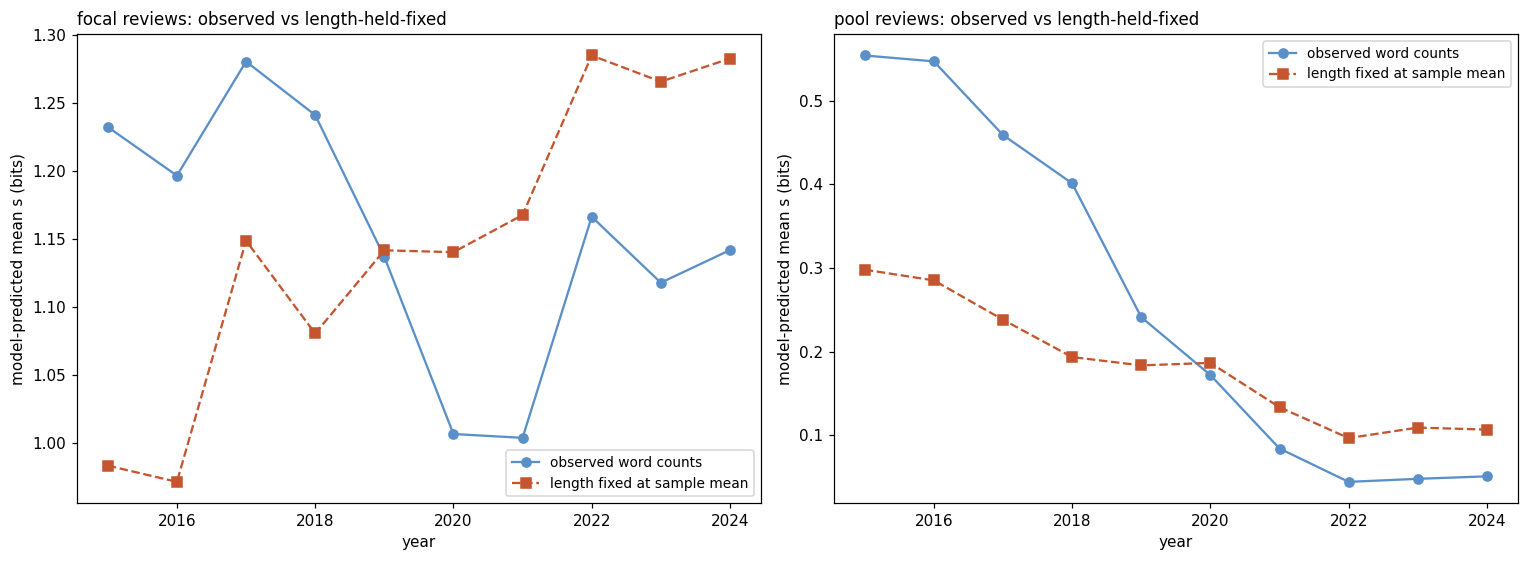

coef      se       p
sample term                                 
focal  year_c         0.0124  0.0080  0.1204
       logW_c         0.3732  0.0251  0.0000
       year_c:logW_c -0.0009  0.0033  0.7848
pool   year_c        -0.0200  0.0037  0.0000
       logW_c         0.2375  0.0213  0.0000
       year_c:logW_c -0.0018  0.0028  0.5077

In [11]:
import statsmodels.formula.api as smf
mdl = df[["s", "year", "word_count", "appid"]].copy()
mdl["logW"] = np.log2(mdl["word_count"].astype(float))
mdl["year_c"] = mdl["year"] - mdl["year"].mean()
mdl["logW_c"] = mdl["logW"] - mdl["logW"].mean()

coefs, dec_rows = {}, {}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=False)
for ax, (name, mask) in zip(axes, [("focal", is_focal), ("pool", ~is_focal)]):
    sub = mdl[mask]
    m = smf.ols("s ~ year_c * logW_c + C(appid)", data=sub).fit(cov_type="cluster", cov_kwds={"groups": sub["appid"]})
    coefs[name] = pd.DataFrame({"coef": m.params, "se": m.bse, "p": m.pvalues}).loc[["year_c", "logW_c", "year_c:logW_c"]]
    m2 = smf.ols("s ~ C(year) * logW_c + C(appid)", data=sub).fit()
    observed = pd.Series(m2.fittedvalues, index=sub.index).groupby(sub["year"]).mean()
    cf = sub.copy(); cf["logW_c"] = 0.0
    fixed = pd.Series(m2.predict(cf), index=sub.index).groupby(sub["year"]).mean()
    dec = pd.DataFrame({"observed": observed, "fixed_length": fixed})
    dec_rows[name] = dec
    ax.plot(dec.index, dec["observed"], "o-", color="#5B8FC7", label="observed word counts")
    ax.plot(dec.index, dec["fixed_length"], "s--", color="#C4552F", label="length fixed at sample mean")
    ax.set_xlabel("year"); ax.set_ylabel("model-predicted mean s (bits)"); ax.legend(fontsize=9)
    ax.set_title(f"{name} reviews: observed vs length-held-fixed", fontsize=11)
    y0, y1 = dec.index.min(), dec.index.max()
    total = dec.loc[y1, "observed"] - dec.loc[y0, "observed"]
    direct = dec.loc[y1, "fixed_length"] - dec.loc[y0, "fixed_length"]
    print(f"{name}: change {y0}->{y1} total {total:+.3f} bits, direct {direct:+.3f}, length-mediated {total - direct:+.3f}"
          + (f" ({(total - direct) / total:.0%} of the total)" if total != 0 else ""))
fig.tight_layout(); fig.savefig(OUT / "time_decomposition15.png", dpi=140); plt.show()

coefs = pd.concat(coefs, names=["sample", "term"])
coefs.round(4).to_csv(OUT / "longitudinal_coefs15.csv")
pd.concat(dec_rows, axis=1).round(4).to_csv(OUT / "time_decomposition15.csv")
df[["cls", "appid", "game", "year", "fold", "word_count", "s", "p_true", "hit", "voted_up", "votes_up", "votes_funny",
    "weighted_vote_score"]].to_parquet(OUT / "review_scores15.parquet", index=False)
coefs.round(4)


## 7. Proximity of focal games to the pools

Two $10\times 5$ matrices with rows summing to one. The design-based one uses the prespecified binary
descriptors (Jaccard overlap, normalised within focal game); it is available before any fitting. The review-based
one applies the auxiliary 5-pool classifier (fitted on pool reviews only, in the fold where the focal review is
held out) and averages its probabilities over each focal game's reviews. A third, optional quantity renormalises
the five pool probabilities of the main 15-class model and is reported with the total pool mass it rests on.

In [12]:
DESC = {
    "F1": "combat shooting survival crafting building exploration",
    "F2": "simulation physics creativity exploration",
    "F3": "combat survival",
    "F4": "combat shooting roleplay narrative exploration crafting building",
    "F5": "combat shooting", "F6": "combat shooting",
    "F7": "roleplay exploration crafting building simulation management farming social",
    "F8": "combat shooting survival crafting building exploration",
    "F9": "social creativity exploration",
    "F10": "combat shooting simulation strategy",
    "G1": "combat shooting", "G2": "roleplay narrative exploration combat",
    "G3": "survival crafting building exploration", "G4": "simulation physics creativity puzzles",
    "G5": "strategy management",
}
DESC = {k: set(v.split()) for k, v in DESC.items()}
J = pd.DataFrame([[Fraction(len(DESC[f] & DESC[g]), len(DESC[f] | DESC[g])) for g in POOLS] for f in FOCAL], index=FOCAL, columns=POOLS)
D = J.apply(lambda r: r / sum(r), axis=1)
desc_tab = D.astype(float).round(4)
desc_tab["max_raw_overlap"] = J.apply(lambda r: float(max(r)), axis=1).round(3)
desc_tab.insert(0, "game", [CLASS_NAME[f] for f in FOCAL])
desc_tab.to_csv(OUT / "proximity_descriptor.csv")
print("exact fractions:"); display(D.astype(str))
desc_tab


exact fractions:


,G1,G2,G3,G4,G5
F1,4/15,1/5,8/15,0,0
F2,0,5/31,5/31,21/31,0
F3,5/11,3/11,3/11,0,0
F4,16/69,32/69,7/23,0,0
F5,5/6,1/6,0,0,0
F6,5/6,1/6,0,0,0
F7,0,99/364,165/364,45/364,55/364
F8,4/15,1/5,8/15,0,0
F9,0,1/3,1/3,1/3,0
F10,35/69,10/69,0,10/69,14/69


,game,G1,G2,G3,G4,G5,max_raw_overlap
F1,7 Days to Die,0.2667,0.2000,0.5333,0.0000,0.0000,0.667
F2,BeamNG.drive,0.0000,0.1613,0.1613,0.6774,0.0000,0.600
F3,Dead by Daylight,0.4545,0.2727,0.2727,0.0000,0.0000,0.333
F4,Fallout 4,0.2319,0.4638,0.3043,0.0000,0.0000,0.571
F5,PAYDAY 2,0.8333,0.1667,0.0000,0.0000,0.0000,1.000
F6,Paladins,0.8333,0.1667,0.0000,0.0000,0.0000,1.000
F7,Stardew Valley,0.0000,0.2720,0.4533,0.1236,0.1511,0.333
F8,Unturned,0.2667,0.2000,0.5333,0.0000,0.0000,0.667
F9,VRChat,0.0000,0.3333,0.3333,0.3333,0.0000,0.167
F10,War Thunder,0.5072,0.1449,0.0000,0.1449,0.2029,0.500


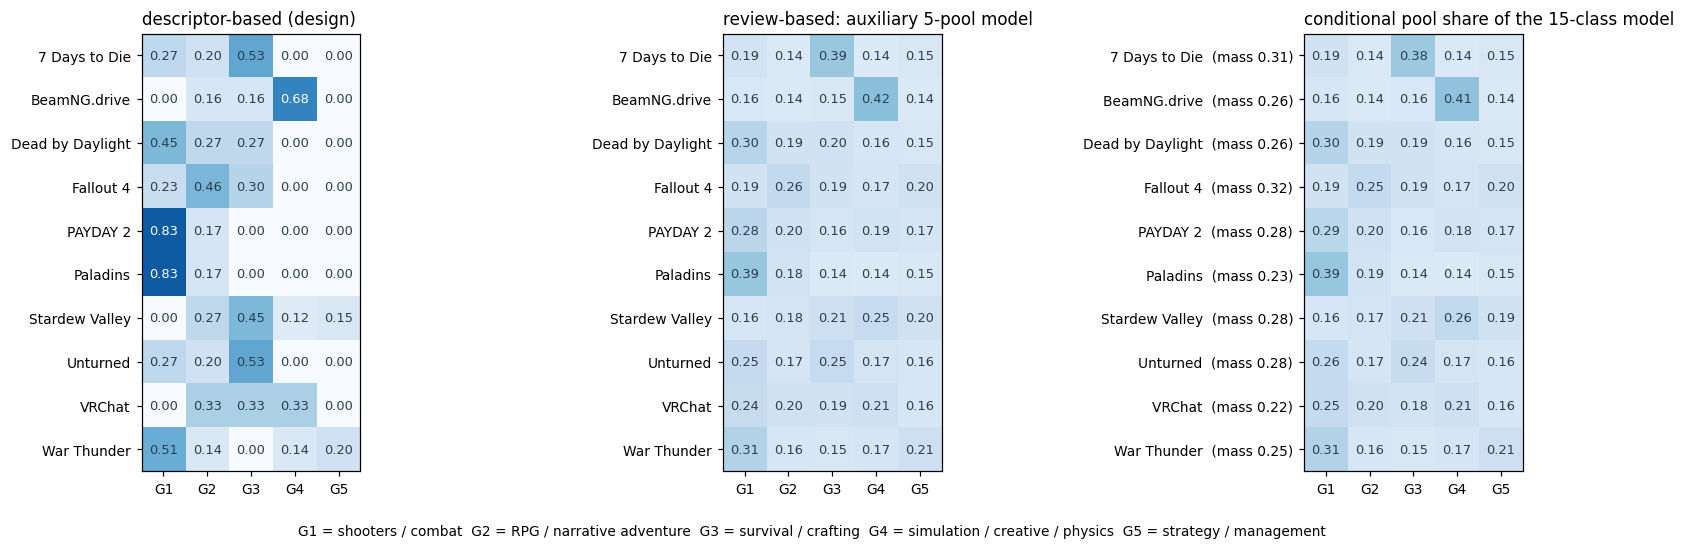

,game,G1,G2,G3,G4,G5,nearest_pool
F1,7 Days to Die,0.1856,0.1383,0.3897,0.1362,0.1502,G3
F2,BeamNG.drive,0.1559,0.1379,0.1496,0.4192,0.1374,G4
F3,Dead by Daylight,0.2955,0.1914,0.2021,0.1605,0.1505,G1
F4,Fallout 4,0.1894,0.2579,0.1903,0.1651,0.1973,G2
F5,PAYDAY 2,0.2832,0.2015,0.1583,0.1855,0.1716,G1
F6,Paladins,0.3937,0.1847,0.1376,0.1363,0.1476,G1
F7,Stardew Valley,0.1619,0.1761,0.2148,0.2485,0.1987,G4
F8,Unturned,0.2501,0.1668,0.2473,0.1746,0.1612,G1
F9,VRChat,0.2432,0.1975,0.1896,0.2098,0.1599,G1
F10,War Thunder,0.3095,0.1609,0.1488,0.1684,0.2124,G1


,game,G1,G2,G3,G4,G5,mean_total_pool_mass
F1,7 Days to Die,0.1911,0.1402,0.3786,0.1382,0.1520,0.3073
F2,BeamNG.drive,0.1583,0.1381,0.1558,0.4097,0.1381,0.2579
F3,Dead by Daylight,0.2978,0.1944,0.1941,0.1624,0.1512,0.2570
F4,Fallout 4,0.1907,0.2550,0.1879,0.1674,0.1990,0.3200
F5,PAYDAY 2,0.2857,0.2025,0.1560,0.1823,0.1735,0.2814
F6,Paladins,0.3908,0.1864,0.1382,0.1356,0.1490,0.2295
F7,Stardew Valley,0.1616,0.1742,0.2061,0.2646,0.1935,0.2763
F8,Unturned,0.2574,0.1659,0.2410,0.1746,0.1610,0.2816
F9,VRChat,0.2507,0.1956,0.1850,0.2065,0.1623,0.2211
F10,War Thunder,0.3121,0.1589,0.1493,0.1680,0.2117,0.2508


In [13]:
# review-based proximity from the auxiliary 5-pool model (eq. 8 of the design note)
Phat = pd.DataFrame([Q[(y == i)].mean(0) for i in range(10)], index=FOCAL, columns=POOLS)
assert np.allclose(Phat.sum(1), 1, atol=1e-4)
# conditional pool confusion of the main model (eq. 11), with the total pool mass
pool_mass = P[:, 10:].sum(1)
Chat = pd.DataFrame([(P[y == i][:, 10:] / pool_mass[y == i, None]).mean(0) for i in range(10)], index=FOCAL, columns=POOLS)
mass = pd.Series([pool_mass[y == i].mean() for i in range(10)], index=FOCAL, name="mean_total_pool_mass")

prox = Phat.round(4).copy()
prox.insert(0, "game", [CLASS_NAME[f] for f in FOCAL])
prox["nearest_pool"] = Phat.idxmax(1)
prox.to_csv(OUT / "proximity_review_based.csv")
cond = Chat.round(4).copy(); cond["mean_total_pool_mass"] = mass.round(4)
cond.insert(0, "game", [CLASS_NAME[f] for f in FOCAL]); cond.to_csv(OUT / "proximity_conditional_main_model.csv")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, M, ttl in [(axes[0], D.astype(float), "descriptor-based (design)"),
                   (axes[1], Phat, "review-based: auxiliary 5-pool model"),
                   (axes[2], Chat, "conditional pool share of the 15-class model")]:
    A = M.to_numpy()
    im = ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(5), POOLS, fontsize=9)
    ax.set_yticks(range(10), [CLASS_NAME[f] for f in FOCAL], fontsize=9)
    for r in range(10):
        for c in range(5):
            ax.text(c, r, f"{A[r, c]:.2f}", ha="center", va="center", fontsize=8.5, color="white" if A[r, c] > 0.55 else "#2C3E50")
    ax.set_title(ttl, fontsize=11)
axes[2].set_yticks(range(10), [f"{CLASS_NAME[f]}  (mass {mass[f]:.2f})" for f in FOCAL], fontsize=9)
fig.suptitle("  ".join(f"{m} = {GROUP_LABELS[m]}" for m in POOLS), fontsize=9, y=0.02)
fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig(OUT / "proximity_heatmaps.png", dpi=140); plt.show()
display(prox); cond


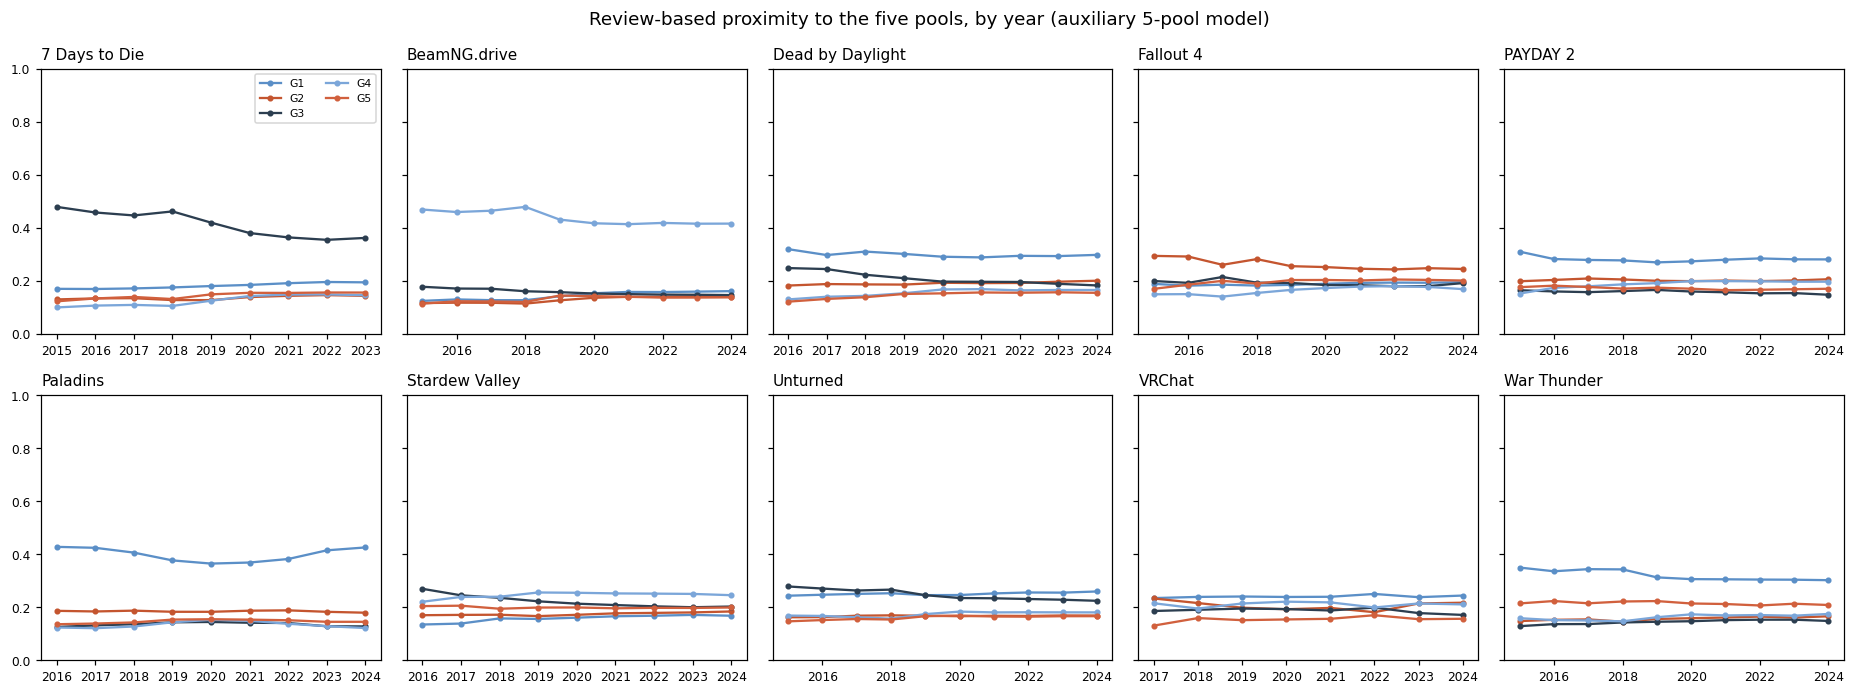

In [14]:
# review-based proximity by year (eq. 10): rows sum to one within each focal game-year
rows = []
for i, f in enumerate(FOCAL):
    for yr in YEARS:
        m = (y == i) & (df["year"].to_numpy() == yr)
        if m.sum():
            rows.append(dict(cls=f, game=CLASS_NAME[f], year=yr, n=int(m.sum()), **dict(zip(POOLS, Q[m].mean(0).round(4)))))
prox_year = pd.DataFrame(rows)
prox_year.to_csv(OUT / "proximity_review_based_by_year.csv", index=False)

fig, axes = plt.subplots(2, 5, figsize=(17, 6.4), sharey=True)
colors = dict(zip(POOLS, ["#5B8FC7", "#C4552F", "#2C3E50", "#7BA6D9", "#D1603D"]))
for ax, f in zip(axes.ravel(), FOCAL):
    t = prox_year[prox_year["cls"] == f]
    for m in POOLS:
        ax.plot(t["year"], t[m], marker="o", ms=3, label=m, color=colors[m])
    ax.set_title(CLASS_NAME[f], fontsize=10); ax.set_ylim(0, 1); ax.tick_params(labelsize=8)
axes[0, 0].legend(fontsize=7, ncol=2)
fig.suptitle("Review-based proximity to the five pools, by year (auxiliary 5-pool model)", fontsize=12)
fig.tight_layout(); fig.savefig(OUT / "proximity_by_year.png", dpi=140); plt.show()


The auxiliary model's own held-out-game performance (5-way, pool reviews only) says how much to trust the
review-based rows: a pool that is poorly recognised when it is the true answer also attracts focal mass unreliably.

In [15]:
q_pool = Q[~is_focal]
yq = y[~is_focal] - 10
aux = pool_df.assign(hit5=(q_pool.argmax(1) == yq), nll5=-np.log2(np.clip(q_pool[np.arange(len(yq)), yq], 1e-12, 1)))
aux_game = aux.groupby(["cls", "appid"]).agg(accuracy5=("hit5", "mean"), log_loss5=("nll5", "mean")).reset_index()
aux_tab = aux_game.groupby("cls").agg(games=("appid", "size"), accuracy_equal_game=("accuracy5", "mean"),
                                     accuracy_se=("accuracy5", lambda v: v.std(ddof=1) / np.sqrt(len(v))),
                                     log_loss_equal_game=("log_loss5", "mean"))
aux_tab.loc["all pools"] = [len(aux_game), aux_game["accuracy5"].mean(), aux_game["accuracy5"].std(ddof=1) / np.sqrt(len(aux_game)), aux_game["log_loss5"].mean()]
aux_tab.to_csv(OUT / "performance_pool5_game_level.csv")
aux_tab.round(4)


,games,accuracy_equal_game,accuracy_se,log_loss_equal_game
cls,,,,
G1,40.0,0.3520,0.0179,2.0699
G2,25.0,0.4090,0.0199,1.9873
G3,6.0,0.3848,0.0346,2.1552
G4,8.0,0.2815,0.0508,2.6687
G5,11.0,0.4228,0.0326,2.0196
all pools,90.0,0.3724,0.0121,2.0997


## 8. Score by funny votes, verdict and helpfulness, across years

The per-review score $s$ of the sampled reviews, grouped by the votes Steam records, shown as box plots side by
side within each year. Box width is proportional to the square root of the group's size in that year, so a thin
box is a small group. The table gives the means and medians by group and year.

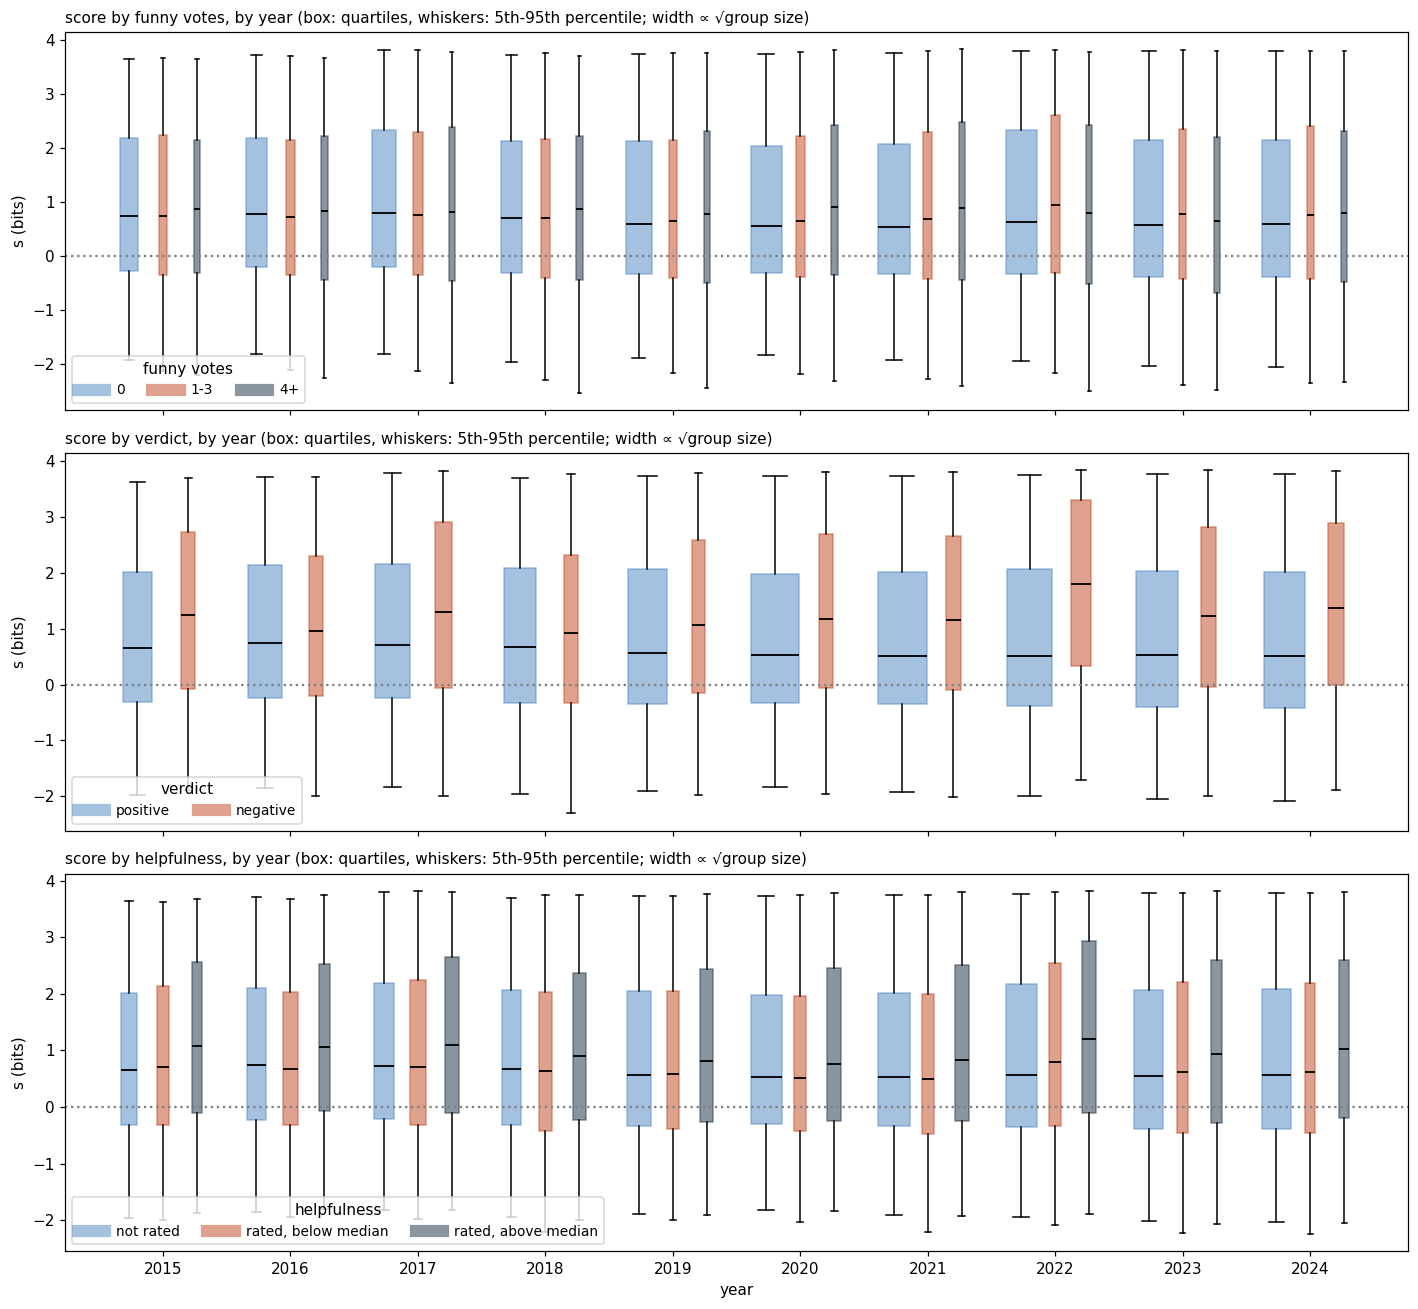

n  mean_s  share_s_pos
grouping    group                                              
funny votes 0                    1342063.0   0.833        0.666
            1-3                   142306.0   0.836        0.667
            4+                     15631.0   0.821        0.666
helpfulness not rated            1017619.0   0.790        0.658
            rated, above median   241137.0   1.054        0.707
            rated, below median   241244.0   0.794        0.658
verdict     negative              196745.0   1.218        0.742
            positive             1303255.0   0.775        0.654

In [16]:
sub = df.copy()
sub["funny"] = sub["votes_funny"].clip(upper=sub["votes_funny"].quantile(0.999))
rated = sub["weighted_vote_score"] > 0
help_med = sub.loc[rated, "weighted_vote_score"].median()
groupings = {
    "funny votes": pd.Series(np.select([sub["funny"] == 0, sub["funny"] <= 3], ["0", "1-3"], "4+"), index=sub.index),
    "verdict": sub["voted_up"].map({True: "positive", False: "negative"}),
    "helpfulness": pd.Series(np.select([~rated, sub["weighted_vote_score"] <= help_med],
                                       ["not rated", "rated, below median"], "rated, above median"), index=sub.index),
}
order = {"funny votes": ["0", "1-3", "4+"], "verdict": ["positive", "negative"],
         "helpfulness": ["not rated", "rated, below median", "rated, above median"]}
palette = ["#5B8FC7", "#C4552F", "#2C3E50"]

rows = []
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for ax, (name, grp) in zip(axes, groupings.items()):
    labs = order[name]
    width_total = 0.8
    cell_n = sub.groupby([grp, sub["year"]]).size()
    n_max = cell_n.max()
    for j, lab in enumerate(labs):
        data, pos, widths = [], [], []
        for yi, yr in enumerate(YEARS):
            v = sub.loc[(grp == lab) & (sub["year"] == yr), "s"].to_numpy()
            if len(v) < 20:
                continue
            data.append(np.clip(v, -8, H_Y)); pos.append(yi + (j - (len(labs) - 1) / 2) * width_total / len(labs))
            widths.append(max(width_total / len(labs) * 0.95 * np.sqrt(len(v) / n_max), 0.05))
            rows.append({"grouping": name, "group": lab, "year": yr, "n": len(v), "mean_s": v.mean(), "median_s": np.median(v), "share_s_pos": (v > 0).mean()})
        bp = ax.boxplot(data, positions=pos, widths=widths, showfliers=False, patch_artist=True, whis=(5, 95),
                        medianprops=dict(color="black", lw=1.2))
        for b in bp["boxes"]:
            b.set(facecolor=palette[j], alpha=0.55, edgecolor=palette[j])
        ax.plot([], [], color=palette[j], lw=8, alpha=0.55, label=lab)
    ax.axhline(0, color="grey", ls=":"); ax.set_ylabel("s (bits)"); ax.legend(title=name, fontsize=9, loc="lower left", ncol=3)
    ax.set_title(f"score by {name}, by year (box: quartiles, whiskers: 5th-95th percentile; width ∝ √group size)", fontsize=10)
axes[-1].set_xticks(range(len(YEARS)), YEARS); axes[-1].set_xlabel("year")
fig.tight_layout(); fig.savefig(OUT / "scores_by_votes_by_year.png", dpi=140); plt.show()

by_group_year = pd.DataFrame(rows)
by_group_year.round(4).to_csv(OUT / "scores_by_group_year.csv", index=False)
by_group = (by_group_year.groupby(["grouping", "group"])
            .apply(lambda t: pd.Series({"n": t["n"].sum(), "mean_s": np.average(t["mean_s"], weights=t["n"]),
                                        "share_s_pos": np.average(t["share_s_pos"], weights=t["n"])})))
by_group.to_csv(OUT / "scores_by_group15.csv")
by_group.round(3)


The same groups drawn **overlapping**: within each year the groups share one position, the largest group is
drawn first and widest, the smaller ones on top and narrower (widths 0.82 / 0.55 / 0.30 in rank order), so each
smaller group sits inside the larger one. Once as box plots, once as violins.

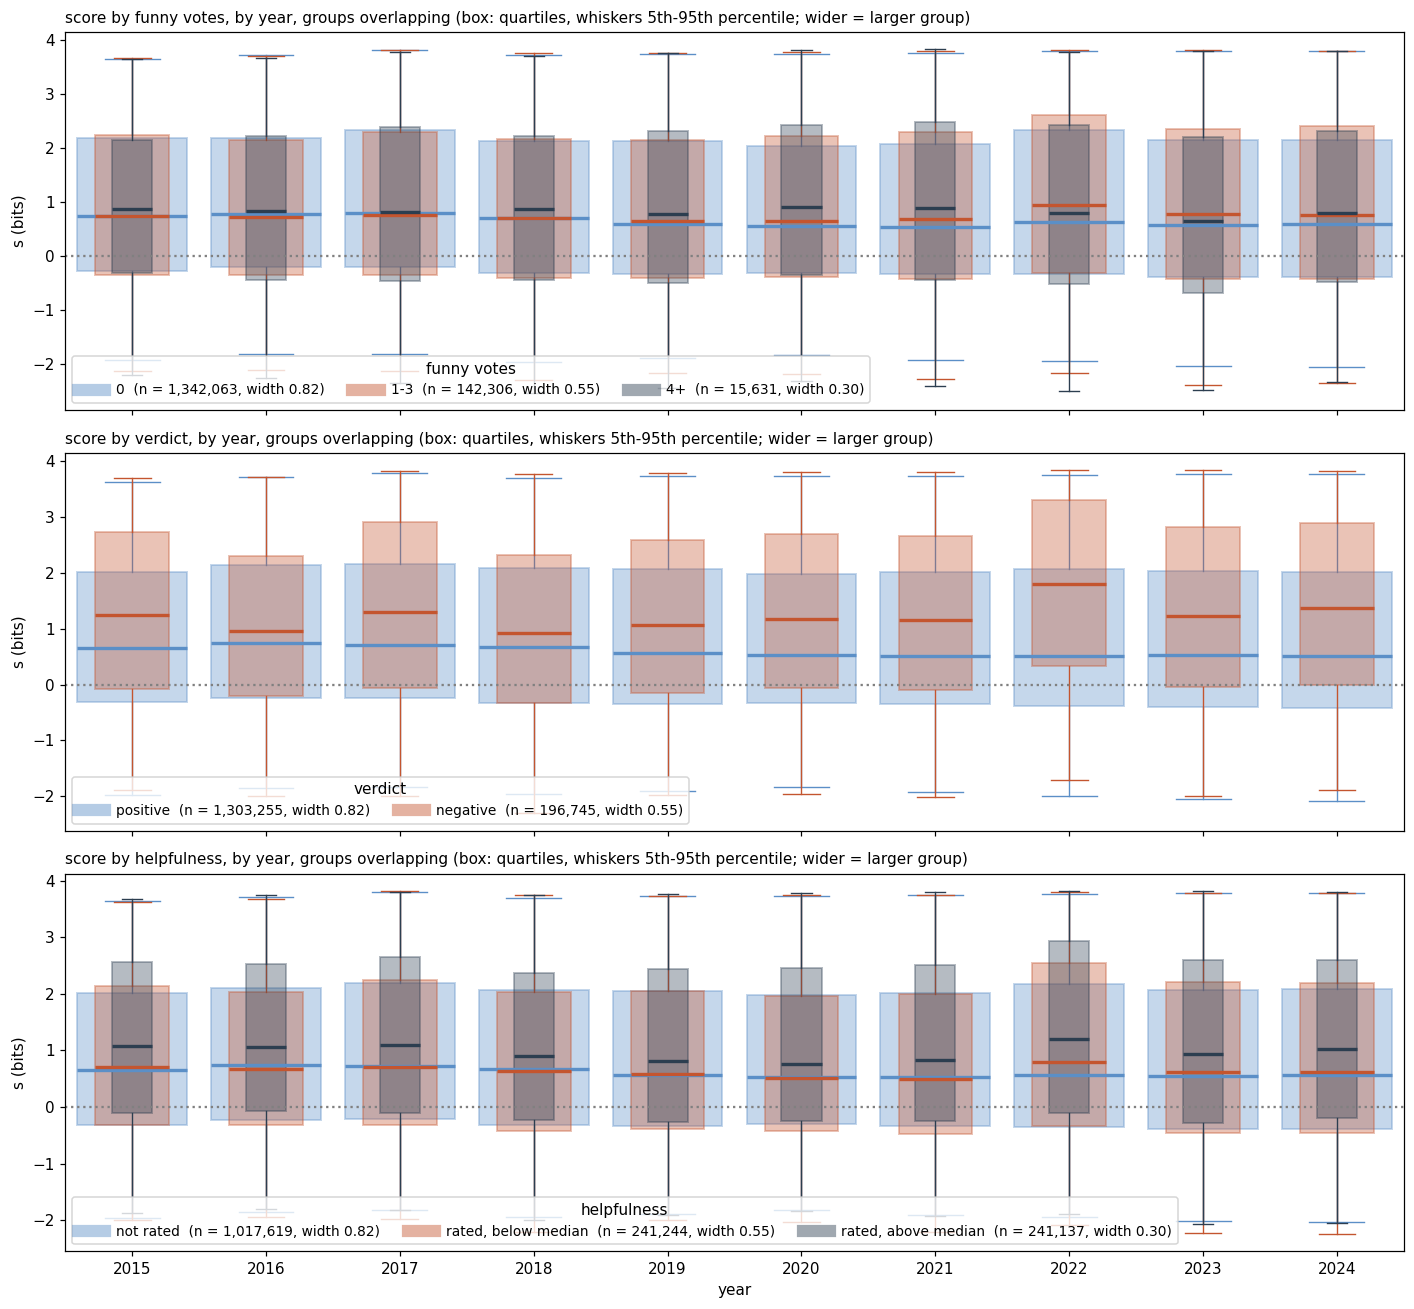

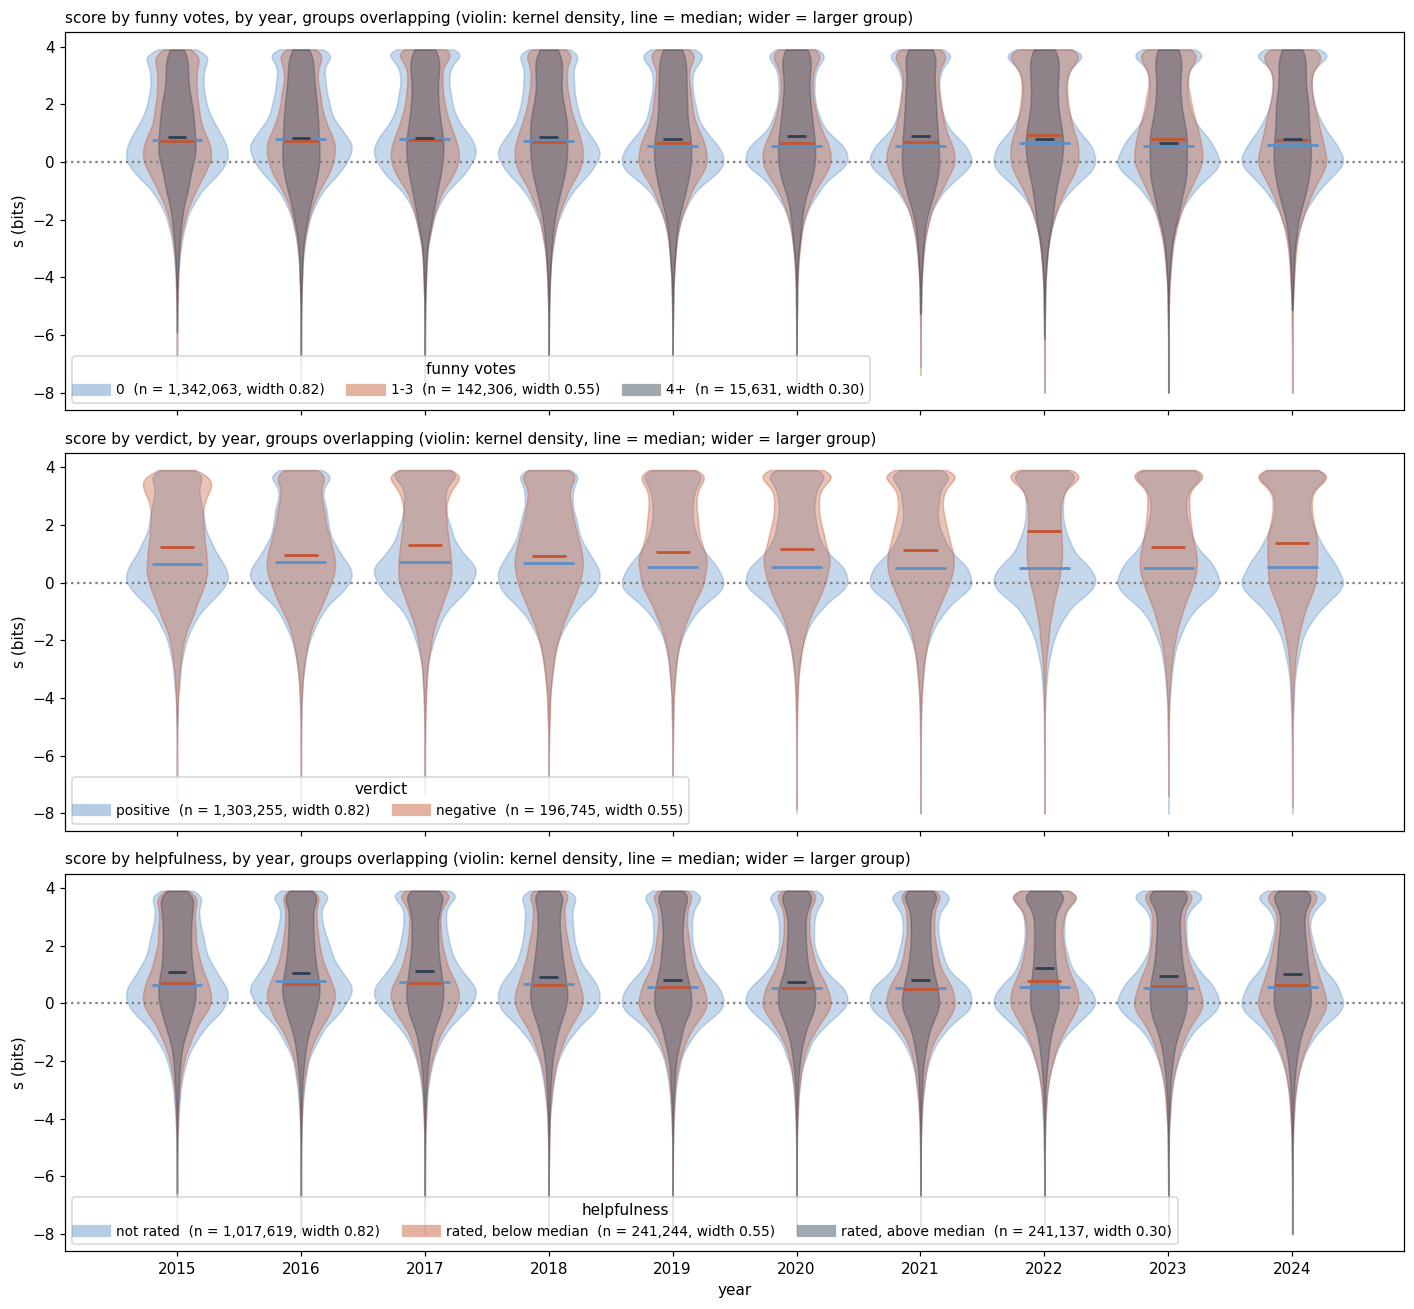

In [17]:
def overlapping(kind, fname):
    fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
    for ax, (name, grp) in zip(axes, groupings.items()):
        labs = order[name]
        sizes = {lab: int((grp == lab).sum()) for lab in labs}
        ranked = sorted(labs, key=lambda l: -sizes[l])
        widths = dict(zip(ranked, [0.82, 0.55, 0.30]))
        for lab in ranked:
            j = labs.index(lab)
            data, pos = [], []
            for yi, yr in enumerate(YEARS):
                v = sub.loc[(grp == lab) & (sub["year"] == yr), "s"].to_numpy()
                if len(v) < 20:
                    continue
                v = np.clip(v, -8, H_Y)
                if kind == "violin" and len(v) > 20000:
                    v = rng.choice(v, 20000, replace=False)
                data.append(v); pos.append(yi)
            if kind == "box":
                bp = ax.boxplot(data, positions=pos, widths=widths[lab], showfliers=False, patch_artist=True, whis=(5, 95),
                                medianprops=dict(color=palette[j], lw=2.2), whiskerprops=dict(color=palette[j], lw=0.9),
                                capprops=dict(color=palette[j], lw=0.9))
                for b in bp["boxes"]:
                    b.set(facecolor=palette[j], alpha=0.35, edgecolor=palette[j], lw=1.3)
            else:
                vp = ax.violinplot(data, positions=pos, widths=widths[lab], showmedians=True, showextrema=False, points=150)
                for b in vp["bodies"]:
                    b.set(facecolor=palette[j], alpha=0.35, edgecolor=palette[j], lw=1.0)
                vp["cmedians"].set(color=palette[j], lw=1.8)
            ax.plot([], [], color=palette[j], lw=8, alpha=0.45, label=f"{lab}  (n = {sizes[lab]:,}, width {widths[lab]:.2f})")
        ax.axhline(0, color="grey", ls=":"); ax.set_ylabel("s (bits)")
        ax.legend(title=name, fontsize=9, loc="lower left", ncol=3)
        what = "box: quartiles, whiskers 5th-95th percentile" if kind == "box" else "violin: kernel density, line = median"
        ax.set_title(f"score by {name}, by year, groups overlapping ({what}; wider = larger group)", fontsize=10)
    axes[-1].set_xticks(range(len(YEARS)), YEARS); axes[-1].set_xlabel("year")
    fig.tight_layout(); fig.savefig(OUT / fname, dpi=140); plt.show()

overlapping("box", "scores_by_votes_overlap_box.png")
overlapping("violin", "scores_by_votes_overlap_violin.png")


The same comparison drawn **per focal game**, in the layout of the per-game distributions: one panel per game,
one position per year, the groups of a vote variable overlapping within the year (largest group widest). One
figure per vote variable.

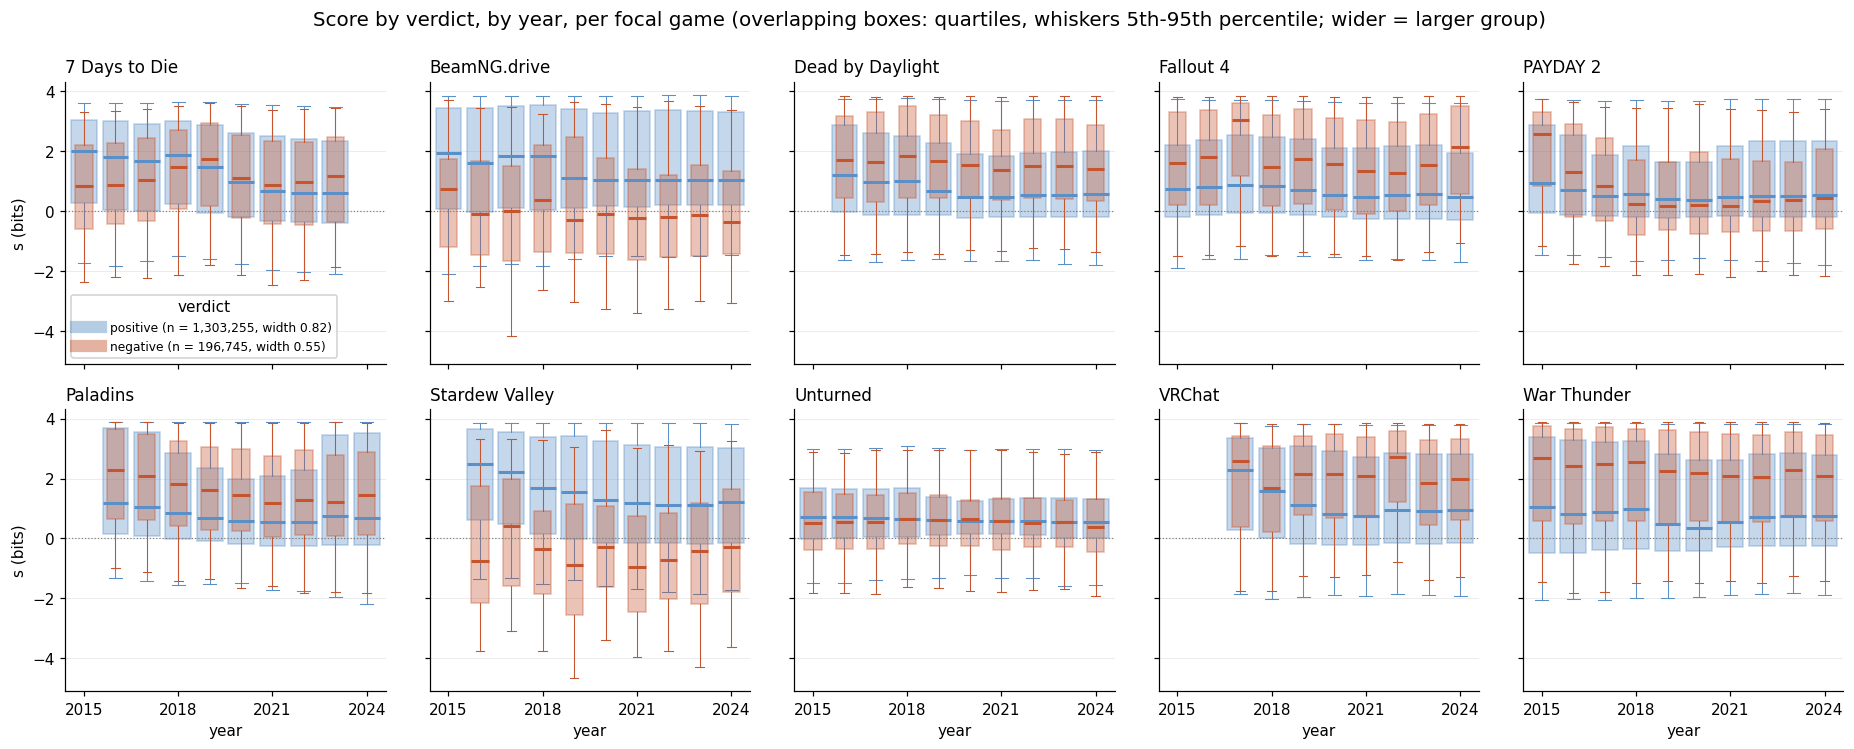

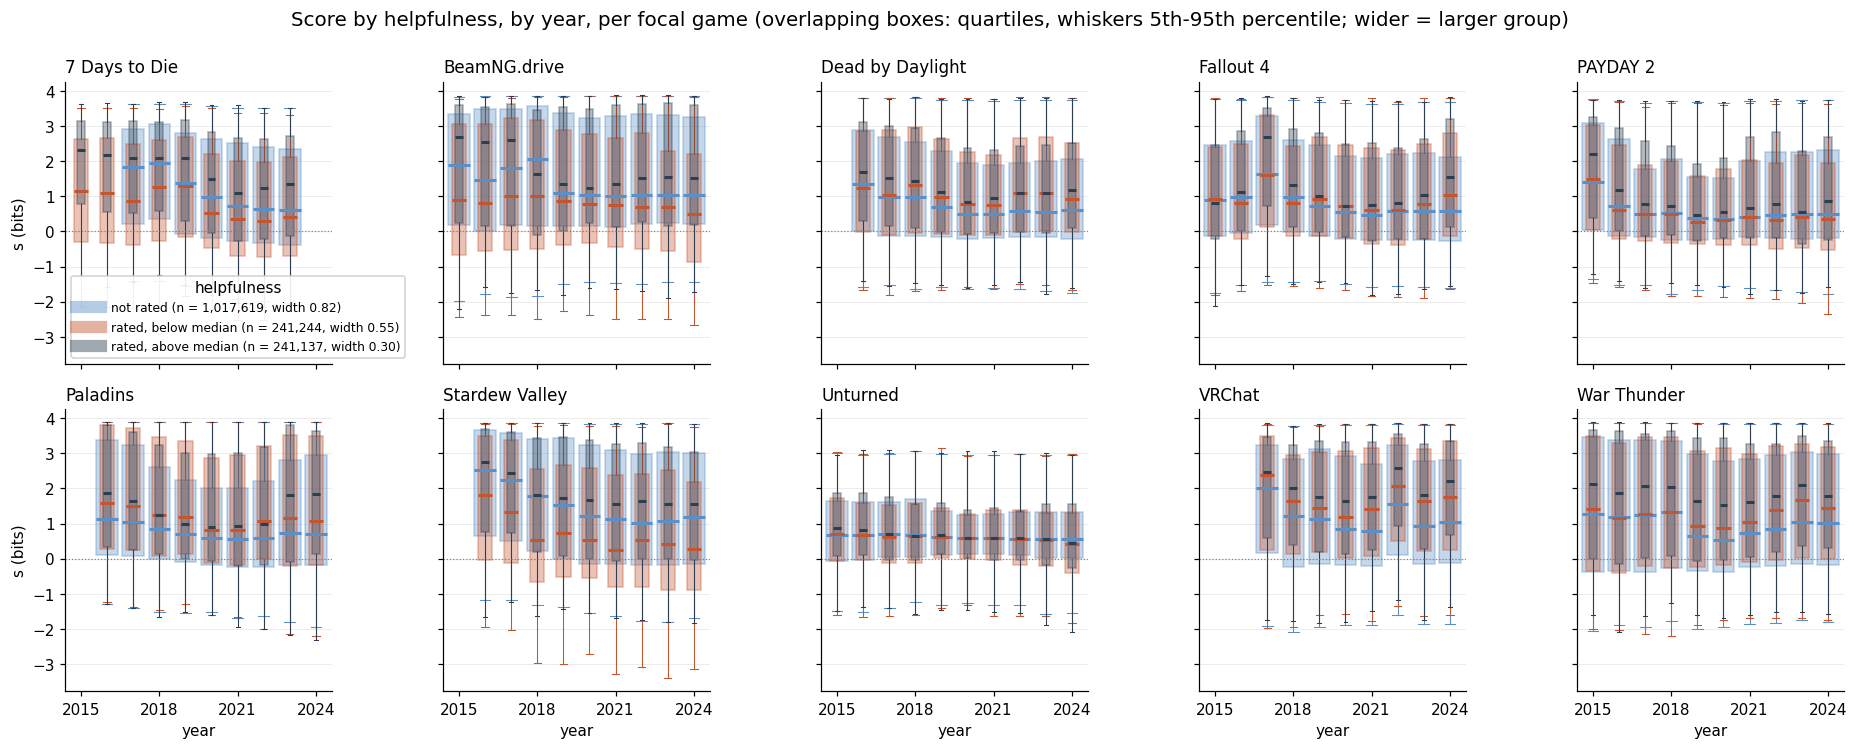

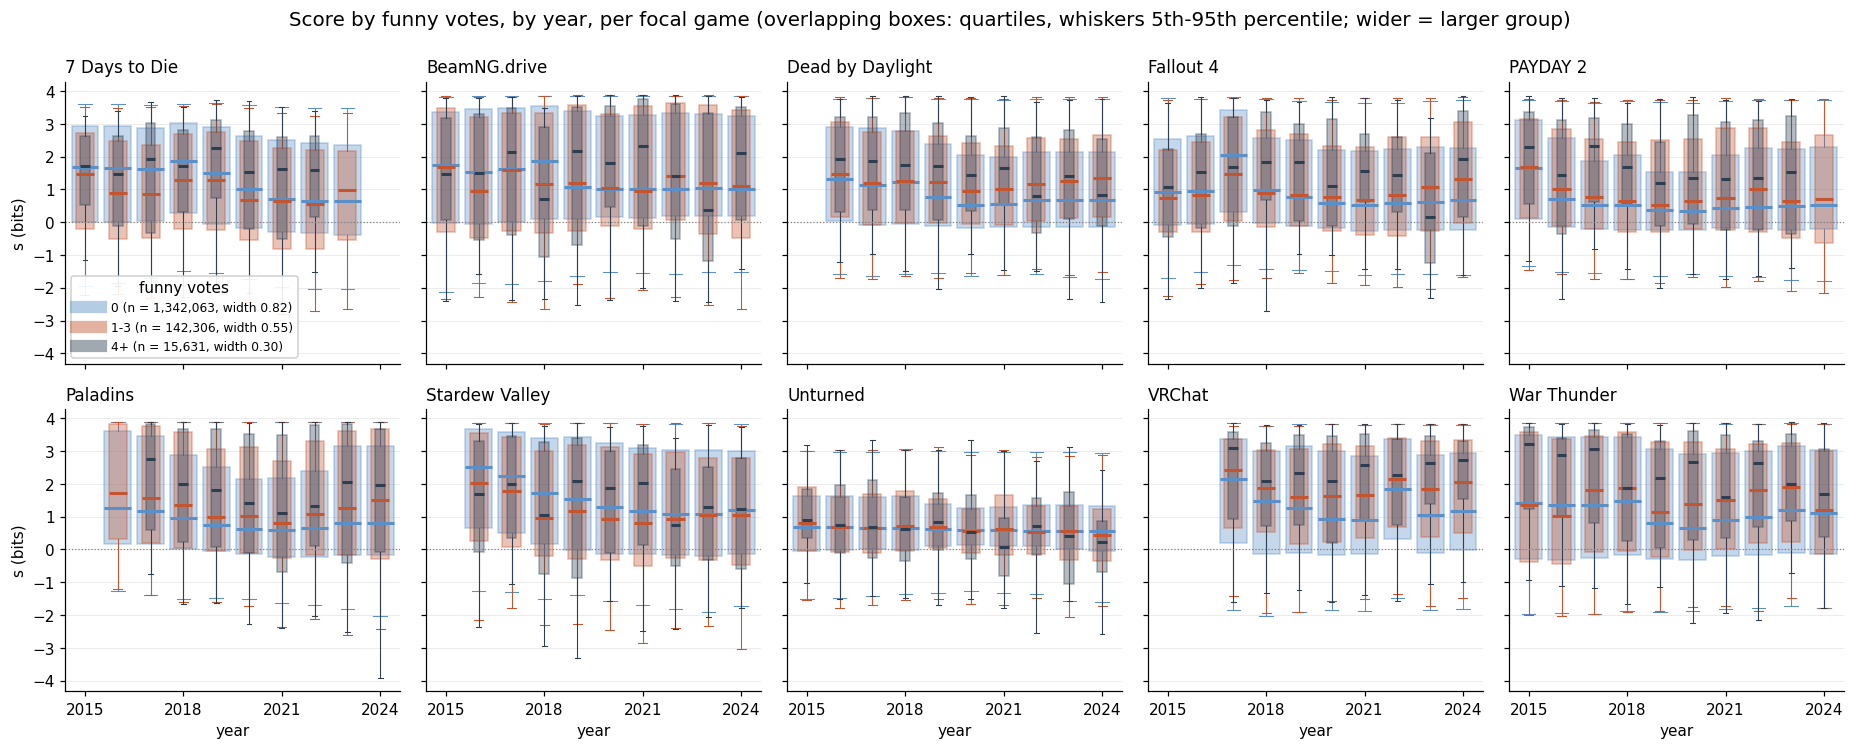

,cls,game,grouping,hi,lo,mean_gap_median_bits,share_years_hi_above,years
0,F1,7 Days to Die,verdict,negative,positive,-0.182,0.556,9
1,F10,War Thunder,verdict,negative,positive,1.579,1.000,10
2,F2,BeamNG.drive,verdict,negative,positive,-1.380,0.000,10
3,F3,Dead by Daylight,verdict,negative,positive,0.868,1.000,9
4,F4,Fallout 4,verdict,negative,positive,1.098,1.000,10
5,F5,PAYDAY 2,verdict,negative,positive,0.114,0.300,10
6,F6,Paladins,verdict,negative,positive,0.837,1.000,9
7,F7,Stardew Valley,verdict,negative,positive,-2.005,0.000,9
8,F8,Unturned,verdict,negative,positive,-0.076,0.200,10
9,F9,VRChat,verdict,negative,positive,0.980,1.000,8


In [18]:
def votes_by_game(name, grp, fname):
    labs = order[name]
    sizes = {lab: int((grp == lab).sum()) for lab in labs}
    ranked = sorted(labs, key=lambda l: -sizes[l])
    widths = dict(zip(ranked, [0.82, 0.55, 0.30]))
    g_arr, s_arr, y_arr, c_arr = grp.to_numpy(), df["s"].to_numpy(), df["year"].to_numpy(), df["cls"].to_numpy()
    fig, axes = plt.subplots(2, 5, figsize=(17, 6.8), sharex=True, sharey=True)
    rows = []
    for ax, f in zip(axes.ravel(), FOCAL):
        for lab in ranked:
            j = labs.index(lab)
            data, pos = [], []
            for yr in YEARS:
                m = (c_arr == f) & (g_arr == lab) & (y_arr == yr)
                if m.sum() < 30:
                    continue
                v = np.clip(s_arr[m], -8, H_Y)
                data.append(v); pos.append(yr)
                rows.append(dict(grouping=name, cls=f, game=CLASS_NAME[f], group=lab, year=yr, n=int(m.sum()),
                                 median_s=float(np.median(v)), mean_s=float(v.mean())))
            if data:
                bp = ax.boxplot(data, positions=pos, widths=widths[lab], showfliers=False, patch_artist=True, whis=(5, 95),
                                medianprops=dict(color=palette[j], lw=2), whiskerprops=dict(color=palette[j], lw=0.7),
                                capprops=dict(color=palette[j], lw=0.7))
                for b in bp["boxes"]:
                    b.set(facecolor=palette[j], alpha=0.35, edgecolor=palette[j], lw=1.1)
        ax.set_title(CLASS_NAME[f], fontsize=11); ax.axhline(0, color="grey", ls=":", lw=0.8)
        ax.set_xlim(2014.4, 2024.6); ax.set_xticks(range(2015, 2025, 3), [str(yy) for yy in range(2015, 2025, 3)]); ax.grid(axis="y", alpha=0.25, lw=0.6); ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    for lab in ranked:
        axes[0, 0].plot([], [], color=palette[labs.index(lab)], lw=8, alpha=0.45, label=f"{lab} (n = {sizes[lab]:,}, width {widths[lab]:.2f})")
    axes[0, 0].legend(fontsize=8, loc="lower left", ncol=1, title=name, framealpha=0.9)
    for ax in axes[-1]:
        ax.set_xlabel("year")
    for ax in axes[:, 0]:
        ax.set_ylabel("s (bits)")
    fig.suptitle(f"Score by {name}, by year, per focal game (overlapping boxes: quartiles, whiskers 5th-95th percentile; wider = larger group)", y=0.995, fontsize=13)
    fig.tight_layout(); fig.savefig(OUT / fname, dpi=140); plt.show()
    return rows

cells = []
cells += votes_by_game("verdict", groupings["verdict"], "votes_by_game_verdict.png")
cells += votes_by_game("helpfulness", groupings["helpfulness"], "votes_by_game_helpfulness.png")
cells += votes_by_game("funny votes", groupings["funny votes"], "votes_by_game_funny.png")
cells = pd.DataFrame(cells)
cells.round(4).to_csv(OUT / "scores_by_game_group_year.csv", index=False)

# per game: median gap between the two groups of interest, averaged over years, and how often the ordering holds
PAIRS = {"verdict": ("negative", "positive"), "helpfulness": ("rated, above median", "not rated"), "funny votes": ("4+", "0")}
summ = []
for name, (hi, lo) in PAIRS.items():
    t = cells[cells["grouping"] == name].pivot_table(index=["cls", "game", "year"], columns="group", values="median_s")
    t = t.dropna(subset=[hi, lo])
    gap = (t[hi] - t[lo]).groupby(level=["cls", "game"])
    out = pd.DataFrame({"mean_gap_median_bits": gap.mean(), "share_years_hi_above": gap.apply(lambda v: (v > 0).mean()), "years": gap.size()})
    out.insert(0, "grouping", name); out.insert(1, "hi", hi); out.insert(2, "lo", lo)
    summ.append(out.reset_index())
summ = pd.concat(summ, ignore_index=True)
summ.round(4).to_csv(OUT / "votes_by_game_summary.csv", index=False)
summ.round(3)


**What this shows.** Within every year the ordering of the groups is the thing to read, since the overall level
of $s$ moves with the class mix of that year. The box widths make visible that the 4+ funny-vote group and the
rated-helpful groups are small; their medians are nonetheless consistently to one side of the unrated majority.

## 9. Files written

In [19]:
for f in sorted(OUT.glob("*")):
    if f.is_file() and f.suffix in (".csv", ".png") and f.stat().st_mtime > (OUT / "sample_15class.parquet").stat().st_mtime:
        print(f"{f.name:48s} {f.stat().st_size / 1e3:8.0f} kB")


boxplots_by_game15.png                                 90 kB
game_level_accuracy.png                                89 kB
heatmap_confusion15.csv                                 2 kB
heatmap_confusion15.png                               217 kB
heatmap_mean_probability15.csv                          2 kB
heatmap_probability15.png                             212 kB
info_by_length15.csv                                    0 kB
info_by_length15.png                                   74 kB
info_by_year15.csv                                      1 kB
info_by_year15.png                                     73 kB
longitudinal_coefs15.csv                                0 kB
p_true_median_by_game_year.csv                          1 kB
performance_per_class.csv                               2 kB
performance_per_game.csv                                8 kB
performance_pool5_game_level.csv                        0 kB
performance_pool_game_level.csv                         2 kB
performance_restricted.c